<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-04/lab-012-onsager.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 012 
<hr/>

# Lab 012 — Onsager's solution of the 2D Ising model

Consider spins $s_i=\pm1$ sitting on the sites of a two-dimensional (2D) square lattice with $N$ sites and periodic boundaries, so that the lattice is a torus.
Neighbouring spins prefer to be parallel, which the Hamiltonian
$$
H(\mathbf s) = -J\sum_{\langle i,j\rangle} s_i s_j
$$
expresses with a coupling energy $J>0$; the sum $\langle i,j\rangle$ runs over the $2N$ nearest-neighbour bonds (each site has 4 neighbours and each bond is shared by 2 sites).
At temperature $T$ a configuration $\mathbf s=(s_1,\dots,s_N)$ occurs with the Boltzmann probability
$$
\begin{aligned}
p(\mathbf s) &= \frac{e^{-\beta H(\mathbf s)}}{Z},\qquad \beta = \frac{1}{k_BT},\\
Z(T) &= \sum_{\mathbf s\in\{\pm1\}^N} e^{-\beta H(\mathbf s)} ,
\end{aligned}
$$
where $k_B$ is the Boltzmann constant. Low energy is favoured, and the more so the lower the temperature.

The figure below shows these objects on a small patch of the lattice. Spins sit on the sites (a filled navy disc is $s_i=+1$, a white disc with an orange rim is $s_i=-1$, the convention of all sketches in this course), and every nearest-neighbour bond contributes $-Js_is_j$ to the energy: $-J$ for a satisfied bond of two parallel spins (solid line) and $+J$ for a broken bond of two antiparallel spins (dashed line with a cross). The faded copies of the first row and of the first column indicate the periodic boundaries.

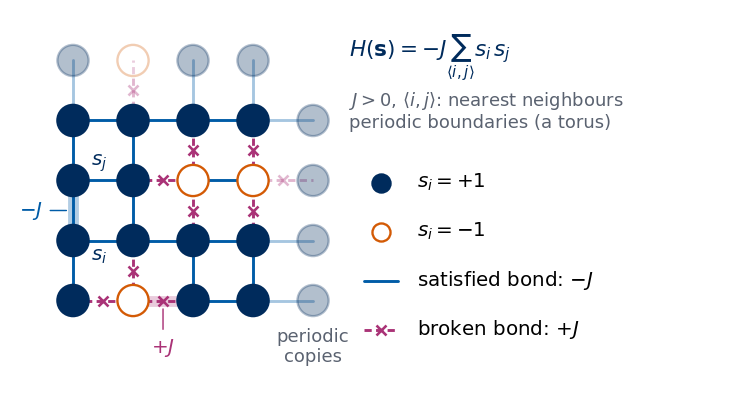

In [ ]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("figures", exist_ok=True)
    for d in ("figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def draw_spin(ax, x, y, s, r=0.26, sign=False, alpha=1.0, fs=10, lw=1.3):
    # one Ising spin at (x, y): navy disc for s = +1, white disc with orange rim for s = -1 (optionally with "+" / "-")
    face, edge, txt = (NAVY, NAVY, "white") if s > 0 else ("white", ORANGE, ORANGE)
    ax.add_patch(mpatches.Circle((x, y), r, fc=face, ec=edge, lw=lw, alpha=alpha, zorder=4))
    if sign:
        ax.text(x, y, "+" if s > 0 else "−", color=txt, ha="center", va="center", alpha=alpha,
                fontsize=fs, fontweight="bold", zorder=5)

def draw_bond(ax, p, q, broken=False, lw=1.5, alpha=1.0, color=None, cross=True):
    # bond between points p and q: solid blue if satisfied, dashed purple with a cross if broken
    c = color or (PURPLE if broken else BLUE)
    ax.plot([p[0], q[0]], [p[1], q[1]], color=c, lw=lw, ls=(0, (2.5, 1.5)) if broken else "-",
            alpha=alpha, solid_capstyle="round", zorder=2)
    if broken and cross:
        ax.plot((p[0] + q[0]) / 2, (p[1] + q[1]) / 2, marker="x", ms=3.5 * lw, mew=lw * 0.9, color=c, alpha=alpha, zorder=3)

def sketch_ising_model():
    # a 4 x 4 patch of the periodic lattice with a fixed, mostly ordered spin pattern; S[y, x], y = row from the bottom
    L = 4
    S = np.ones((L, L), int)
    S[2, 2] = S[2, 3] = -1                                          # a small domain of two flipped spins
    S[0, 1] = -1                                                    # and one isolated flipped spin
    fig = plt.figure(figsize=(5.5, 2.9))
    ax = fig.add_axes([0.0, 0.0, 0.47, 1.0]); tx = fig.add_axes([0.47, 0.0, 0.53, 1.0]); tx.axis("off")

    # nearest-neighbour bonds inside the patch (right and up neighbours) and the periodic bonds to the ghost copies
    for y in range(L):
        for x in range(L):
            for dx, dy in [(1, 0), (0, 1)]:
                xn, yn = x + dx, y + dy
                s_n = S[yn % L, xn % L]                               # periodic boundaries: index modulo L
                ghost = xn == L or yn == L
                draw_bond(ax, (x, y), (xn, yn), broken=S[y, x] * s_n < 0, lw=1.6, alpha=0.35 if ghost else 1.0)
    # ghost copies of column 1 (right) and row 1 (top): the same spins seen again through the periodic boundary
    for k in range(L):
        draw_spin(ax, L, k, S[k, 0], alpha=0.3); draw_spin(ax, k, L, S[0, k], alpha=0.3)
    for y in range(L):
        for x in range(L):
            draw_spin(ax, x, y, S[y, x])
    ax.text(L, -0.45, "periodic\ncopies", ha="center", va="top", fontsize=10, color=GRAY)

    # one satisfied and one broken bond, annotated with their energies
    i, j = (0, 1), (0, 2)                                           # s_i = s_j = +1: a satisfied bond
    ax.plot(*zip(i, j), color=BLUE, lw=6, alpha=0.3, zorder=1)
    ax.annotate(r"$-J$", xy=(-0.05, 1.5), xytext=(-0.5, 1.5), fontsize=11, ha="right", va="center", color=BLUE,
                arrowprops=dict(arrowstyle="-", color=BLUE, lw=0.8))
    ax.text(i[0] + 0.3, i[1] - 0.1, "$s_i$", fontsize=11, ha="left", va="top", color=NAVY)
    ax.text(j[0] + 0.3, j[1] + 0.1, "$s_j$", fontsize=11, ha="left", va="bottom", color=NAVY)
    k, l = (1, 0), (2, 0)                                           # s = -1 next to s = +1: a broken bond
    ax.plot(*zip(k, l), color=PURPLE, lw=6, alpha=0.25, zorder=1)
    ax.annotate(r"$+J$", xy=(1.5, -0.08), xytext=(1.5, -0.6), fontsize=11, ha="center", va="top", color=PURPLE,
                arrowprops=dict(arrowstyle="-", color=PURPLE, lw=0.8))
    ax.set_xlim(-1.0, L + 0.6); ax.set_ylim(-1.15, L + 0.45); ax.set_aspect("equal"); ax.axis("off")

    # Hamiltonian and legend
    tx.set_xlim(0, 1); tx.set_ylim(0, 1)
    tx.text(0.0, 0.88, r"$H(\mathbf{s})=-J\sum_{\langle i,j\rangle}s_i\,s_j$", fontsize=12, color=NAVY, va="center")
    tx.text(0.0, 0.74, r"$J>0$, $\langle i,j\rangle$: nearest neighbours" "\nperiodic boundaries (a torus)", fontsize=10, color=GRAY, va="center")
    rows = [("spin", +1, r"$s_i=+1$"), ("spin", -1, r"$s_i=-1$"),
            ("bond", False, r"satisfied bond: $-J$"), ("bond", True, r"broken bond: $+J$")]
    for n, (kind, val, label) in enumerate(rows):
        yy = 0.55 - 0.13 * n
        if kind == "spin":
            tx.plot(0.085, yy, "o", ms=10, mfc=NAVY if val > 0 else "white", mec=NAVY if val > 0 else ORANGE, mew=1.3)
        else:
            draw_bond(tx, (0.04, yy), (0.13, yy), broken=val, lw=1.6)
        tx.text(0.18, yy, label, fontsize=11, va="center")
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_ising_model()
save_sketch(fig, "sketch_ising_card.png")
plt.show()


The whole story of this notebook is about the normalisation $Z$ of this distribution, the partition function, a sum over all $2^N$ configurations.
We shall see in Section 1 that every thermodynamic quantity — energy, specific heat, magnetisation — is a derivative of $\ln Z$, so that knowing $Z(T)$ means knowing everything.
The central quantity is the free energy per spin $f = -\frac{T}{N}\ln Z$ (with $k_B=1$) in the limit $N\to\infty$: the energy follows as $u = \partial(\beta f)/\partial\beta$,
the specific heat as $c = \partial u/\partial T$, and a phase transition is a temperature at which $f(T)$ fails to be an analytic function.

Already for $N = 100$ spins the sum has $2^{100}\approx1.3\times10^{30}$ terms, so $Z$ cannot be computed term by term. To *solve* the model means to find $f$ in closed
form for $N\to\infty$, and this is what Onsager achieved for the square lattice [Onsager 1944]:
$$
\begin{aligned}
-\beta f &= \ln(2\cosh2K) + \frac{1}{2\pi}\int_0^\pi d\phi\,\ln\Big[\tfrac12\Big(1+\sqrt{1-\kappa^2\sin^2\phi}\Big)\Big],\\
K &= \beta J,\qquad \kappa = \frac{2\sinh2K}{\cosh^22K}.
\end{aligned}
$$
The integrand is smooth except when $\kappa = 1$, which happens at a single temperature, $\sinh 2K_c = 1$, that is
$T_c = 2J/\big(k_B\ln(1+\sqrt2)\big) \approx 2.269\,J/k_B$.

The formula matters for three reasons. The first is conceptual. Each Boltzmann weight $e^{-\beta H}$ is an analytic function of $T$, and for finite $N$ so is $\ln Z$
(Section 1); a sharp transition, a kink or a divergence in a thermodynamic quantity, can therefore exist only in the limit $N\to\infty$. Peierls [1936] had argued that the
2D model orders at low temperature, and Kramers and Wannier [1941] had located $T_c$ by a symmetry argument, but Onsager's formula was the first exact free energy of a
model with a phase transition, and with it the non-analyticity could be seen explicitly. The second reason is that the exact solution yields exact critical exponents.
Near $T_c$ it gives a logarithmically divergent specific heat and, together with Yang's magnetisation [Yang 1952], $M\propto(T_c-T)^{1/8}$, whereas mean-field theory,
the standard approximation, predicts a finite jump in the specific heat and $M\propto(T_c-T)^{1/2}$ (Section 9). This disagreement is a central motivation of the theory of
scaling and of the renormalisation group [Kardar 2007]. The third reason is practical: exact results are rare, so every numerical method for lattice models — Monte Carlo
sampling, transfer matrices, and the neural networks of this course — is tested against Onsager's solution. In particular, $T_c\approx2.269$ is the temperature that the
convolutional neural network (CNN) of Lab 011 should locate from the Monte Carlo spin images of Lab 010.

We shall not reproduce Onsager's derivation, which fills a 33-page paper. Instead we build the ideas behind it one at a time, derive in full what can be derived in a few
lines, summarise the rest through its key equations, and confirm every result twice: symbolically with the computer-algebra library SymPy, which checks the exact algebra
of each derivation, and numerically, against brute-force enumeration, the transfer matrix or Onsager's formula. The route is as follows. Section 1 explains what it means
to solve the model, computes $\ln Z$ of a finite lattice by brute force and shows why it is always smooth. Section 2 introduces the transfer matrix on the one-dimensional
(1D) chain, where the free energy and the correlation length can be found exactly and there is no transition. Section 3 carries the method to 2D, with transfer matrices of
size $2^L\times2^L$ for strips of width $L$, and compares one dimension with two. Section 4 develops the high- and low-temperature expansions of $Z$, and Section 5 turns
their resemblance into Kramers–Wannier duality and the self-dual point $\sinh 2K_c = 1$. Section 6 outlines the free-fermion derivation of Onsager's formula and extracts
from it $f$, $u$, $c$ and Yang's magnetisation $M$. Section 7 obtains the energy at the critical point, $u(T_c) = -\sqrt2\,J$, both from the solution and from duality alone.
Section 8 computes the critical exponents from the exact formulas and from the transfer matrix, Section 9 confronts mean-field theory with the exact solution, and
Section 10 tests universality on the triangular lattice.

Throughout we use units $J = k_B = 1$ and zero magnetic field $h = 0$ unless stated otherwise, so that $K = J/(k_BT) = 1/T$ is the dimensionless coupling.

### References

* E. Ising, Z. Phys. **31**, 253 (1925), [doi:10.1007/BF02980577](https://doi.org/10.1007/BF02980577) — the 1D chain.
* R. Peierls, Math. Proc. Camb. Phil. Soc. **32**, 477 (1936), [doi:10.1017/S0305004100019174](https://doi.org/10.1017/S0305004100019174) — order at low $T$ in 2D;
  R. B. Griffiths, Phys. Rev. **136**, A437 (1964), [doi:10.1103/PhysRev.136.A437](https://doi.org/10.1103/PhysRev.136.A437) — its rigorous form.
* H. A. Kramers, G. H. Wannier, Phys. Rev. **60**, 252 (1941), [doi:10.1103/PhysRev.60.252](https://doi.org/10.1103/PhysRev.60.252) — duality and $T_c$.
* L. Onsager, Phys. Rev. **65**, 117 (1944), [doi:10.1103/PhysRev.65.117](https://doi.org/10.1103/PhysRev.65.117) — the free energy.
* B. Kaufman, Phys. Rev. **76**, 1232 (1949), [doi:10.1103/PhysRev.76.1232](https://doi.org/10.1103/PhysRev.76.1232) — the transfer-matrix spectrum by spinor analysis.
* R. M. F. Houtappel, Physica **16**, 425 (1950), [doi:10.1016/0031-8914(50)90130-3](https://doi.org/10.1016/0031-8914(50)90130-3) — the triangular lattice.
* C. N. Yang, Phys. Rev. **85**, 808 (1952), [doi:10.1103/PhysRev.85.808](https://doi.org/10.1103/PhysRev.85.808) — the spontaneous magnetisation.
* T. D. Schultz, D. C. Mattis, E. H. Lieb, Rev. Mod. Phys. **36**, 856 (1964), [doi:10.1103/RevModPhys.36.856](https://doi.org/10.1103/RevModPhys.36.856) — the solution as a problem of free fermions.
* J. L. Cardy, J. Phys. A **17**, L385 (1984), [doi:10.1088/0305-4470/17/7/003](https://doi.org/10.1088/0305-4470/17/7/003);
  H. W. J. Blöte, J. L. Cardy, M. P. Nightingale, Phys. Rev. Lett. **56**, 742 (1986), [doi:10.1103/PhysRevLett.56.742](https://doi.org/10.1103/PhysRevLett.56.742);
  I. Affleck, Phys. Rev. Lett. **56**, 746 (1986), [doi:10.1103/PhysRevLett.56.746](https://doi.org/10.1103/PhysRevLett.56.746) — finite-size amplitudes at criticality.
* R. J. Baxter, J. Stat. Phys. **145**, 518 (2011), [doi:10.1007/s10955-011-0213-z](https://doi.org/10.1007/s10955-011-0213-z), [arXiv:1103.3347](https://arxiv.org/abs/1103.3347) — history of the magnetisation formula.
* Textbooks: R. J. Baxter, *Exactly Solved Models in Statistical Mechanics* (Academic Press, 1982, ISBN 0-12-083180-5; Dover reprint 2007, ISBN 978-0-486-46271-4);
  K. Huang, *Statistical Mechanics*, 2nd ed. (Wiley, 1987, ISBN 0-471-81518-7);
  M. Kardar, *Statistical Physics of Fields* (Cambridge University Press, 2007), [doi:10.1017/CBO9780511815881](https://doi.org/10.1017/CBO9780511815881).
* Open derivations: W. Gispen, *Kramers–Wannier and Jordan–Wigner*, bachelor thesis, Radboud University (2018),
  [PDF](https://www.math.ru.nl/~mueger/THESES/Willem_Gispen_Bachelor_2018.pdf) (transfer matrix, duality and the fermion transformation in full detail);
  M. E. Peskin, Physics 212 lecture notes, *Solution of the 2-dimensional Ising model*, [PDF](https://s3df.slac.stanford.edu/people/mpeskin/Physics212/Ising2d.pdf).

> **How to run this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook* (or open it from Google Drive).
> 2. Run cells one by one with **Shift + Enter**. Run them *in order* — later cells use variables defined earlier.
> 3. Only `numpy`, `scipy`, `sympy` and `matplotlib` are needed; they are pre-installed in Colab, no `pip install` required. No data are downloaded.
> 4. The slowest cells (transfer matrices of size $2^{10}\times2^{10}$ and $2^{12}\times2^{12}$) print their running time.
> 5. If the notebook state becomes inconsistent: *Runtime → Restart session* and run from the top.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.integrate import quad
from scipy.special import ellipkm1
from scipy.integrate import IntegrationWarning
import warnings
from scipy.optimize import brentq
from scipy.linalg import eigh
from scipy.sparse.linalg import eigs, eigsh
import sympy as sp
from IPython.display import display

# UJ colours
UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
blues = LinearSegmentedColormap.from_list("uj_blues", ["#9CC3E6", UJNavy])   # light -> dark: small L -> large L
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": UJGray, "axes.titlesize": 11, "axes.titlecolor": UJNavy,
                     "axes.prop_cycle": plt.cycler(color=[UJBlue, DSOrange, UJNavy, UJGray])})

TC = 2.0 / np.log(1.0 + np.sqrt(2.0))      # Onsager's critical temperature (derived in Section 5)
KC = 1.0 / TC
print(f"T_c = 2/ln(1+sqrt 2) = {TC:.10f},   K_c = 1/T_c = {KC:.10f}")

T_c = 2/ln(1+sqrt 2) = 2.2691853142,   K_c = 1/T_c = 0.4406867935


<hr/>
## 1. The partition function and exact solutions

Before computing anything we should be clear about what we are after. In this section we show that all of thermodynamics is contained in $\ln Z$, give a mathematical
definition of a phase transition, and compute $Z$ exactly for the smallest lattices. The lesson — a finite lattice never has a transition — tells us what the later sections
must achieve.

Write $E(\mathbf s)=H(\mathbf s)$ and $\langle A\rangle = \sum_{\mathbf s}A(\mathbf s)\,p(\mathbf s)$ for the thermal average. Differentiating $Z=\sum_{\mathbf s}e^{-\beta E(\mathbf s)}$
with respect to $\beta$ brings down a factor $-E$, so $\ln Z$ generates the averages:
$$
\begin{aligned}
\frac{\partial\ln Z}{\partial\beta} &= \frac{1}{Z}\sum_{\mathbf s}\big(-E(\mathbf s)\big)e^{-\beta E(\mathbf s)} = -\langle E\rangle,\\
\frac{\partial^2\ln Z}{\partial\beta^2} &= \langle E^2\rangle-\langle E\rangle^2 \;\ge 0 .
\end{aligned}
$$
The second derivative is the derivative of $-\langle E\rangle$, and differentiating the ratio produces the variance.
In terms of the free energy per spin $f = -\frac{1}{N\beta}\ln Z$, the energy per spin and the specific heat per spin are therefore
$$
\begin{aligned}
u &= \frac{\langle E\rangle}{N} = \frac{\partial(\beta f)}{\partial\beta},\\
c &= \frac{\partial u}{\partial T} = \frac{\partial u}{\partial\beta}\frac{d\beta}{dT} = \frac{\langle E^2\rangle-\langle E\rangle^2}{NT^2},
\end{aligned}
$$
where we used $d\beta/dT=-1/T^2$. The specific heat is thus a variance, and a large $c$ signals large energy fluctuations.
In the same way a magnetic field $h$, added as $-h\sum_is_i$ to $H$, gives the magnetisation per spin $m = \frac1N\frac{\partial\ln Z}{\partial(\beta h)} = \frac1N\big\langle\sum_is_i\big\rangle$.

Because $\ln Z$ grows proportionally to $N$ (it is *extensive*), the per-spin quantities $f$, $u$, $c$ have finite limits as $N\to\infty$, and these limits describe
a macroscopic sample with $N\sim10^{23}$ spins.

A phase transition is a temperature $T_c$ at which $f(T)$ is not analytic, so that some derivative of $f$ jumps or diverges.
For finite $N$ this cannot happen: $Z(\beta)=\sum_E n_E e^{-\beta E}$ is a finite sum of exponentials, each analytic in $\beta$, and $Z>0$ for real $\beta$,
so $\ln Z$ is analytic with all derivatives finite. A *limit* of analytic functions, however, need not be analytic. Consider
$$
f_N(x) = \frac1N\ln\big(e^{Nx}+e^{-Nx}\big)\ \xrightarrow{N\to\infty}\ |x| .
$$
Each $f_N$ is smooth, yet the limit has a kink at $x=0$, and the approach is uniform, $0\le f_N(x)-|x|\le\frac{\ln 2}{N}$. A phase transition is this mechanism at
work in $\ln Z/N$. The cell below plots $f_N$ for growing $N$ and prints the largest deviation from $|x|$, which should saturate the bound $\ln2/N$ (it does, at $x=0$).

N =   1: max |f_N(x) - |x|| = 0.69315   (bound ln2/N = 0.69315)
N =   3: max |f_N(x) - |x|| = 0.23105   (bound ln2/N = 0.23105)
N =  10: max |f_N(x) - |x|| = 0.06931   (bound ln2/N = 0.06931)
N = 100: max |f_N(x) - |x|| = 0.00693   (bound ln2/N = 0.00693)


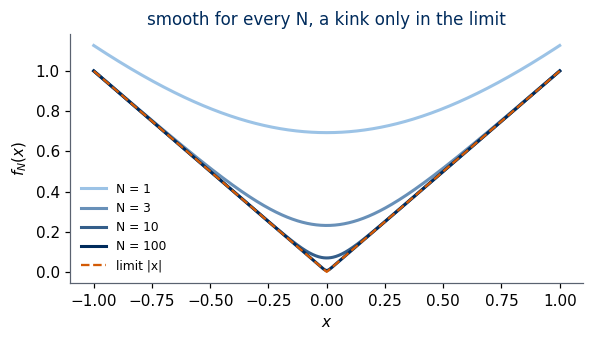

In [2]:
# a limit of smooth functions can have a kink: f_N(x) = (1/N) ln(e^{Nx} + e^{-Nx}) -> |x|
x = np.linspace(-1, 1, 801)
fig, ax = plt.subplots(figsize=(5.5, 3.2))
for i, Nx in enumerate([1, 3, 10, 100]):
    fN = np.logaddexp(Nx * x, -Nx * x) / Nx
    ax.plot(x, fN, color=blues(i / 3), lw=2, label=f"N = {Nx}")
    print(f"N = {Nx:3d}: max |f_N(x) - |x|| = {np.max(np.abs(fN - np.abs(x))):.5f}   (bound ln2/N = {np.log(2)/Nx:.5f})")
ax.plot(x, np.abs(x), color=DSOrange, ls="--", lw=1.5, label="limit |x|")
ax.set_xlabel("$x$"); ax.set_ylabel("$f_N(x)$"); ax.legend(frameon=False, fontsize=8)
ax.set_title("smooth for every N, a kink only in the limit")
plt.tight_layout(); plt.show()

### 1.1 Exact enumeration of a small lattice
On an $L\times L$ torus there are $2^{L^2}$ configurations, which for $L = 4$ makes $65\,536$ — few enough to list them all. We store every configuration as a row of $\pm1$:
the bits of the integer $n\in\{0,\dots,2^N-1\}$ give the spins through $s = 1-2\,\text{bit}$.

Rather than keeping all energies, it pays to count broken bonds. A bond $\langle i,j\rangle$ is *satisfied* if $s_is_j=+1$ (energy $-1$) and *broken* if $s_is_j=-1$ (energy $+1$).
With $b$ broken bonds out of $2N$ the energy is $E = -(2N-b) + b = -2N + 2b$, so $E$ depends only on $b$, and $Z$ is fixed by the histogram
$n_b$, the number of configurations with $b$ broken bonds (the *density of states*):
$$
Z(T) = \sum_{b=0}^{2N} n_b\, e^{-(-2N+2b)/T}.
$$
Two features of the histogram can be predicted in advance. Every configuration and its global flip $\mathbf s\to-\mathbf s$ have the same $b$, so every $n_b$ is even.
Moreover, on the square-lattice torus $b$ itself is always even: the product of $s_is_j$ over all $2N$ bonds is $\prod_i s_i^4=1$, so the number of factors equal to $-1$
is even. The printed histogram for $4\times4$ shows both properties; note also its symmetry $n_b = n_{32-b}$.

In [3]:
def all_configs(n):
    # all 2^n configurations of n spins, as rows of +-1 (bit k of the row index -> spin k)
    bits = (np.arange(2**n)[:, None] >> np.arange(n)) & 1
    return (1 - 2 * bits).astype(np.int8)

def torus_energies(L):
    # energies of all 2^(L*L) configurations of the L x L periodic square lattice (J = 1)
    S = all_configs(L * L).reshape(-1, L, L).astype(np.int32)
    return -(S * np.roll(S, 1, axis=1)).sum(axis=(1, 2)) - (S * np.roll(S, 1, axis=2)).sum(axis=(1, 2))

dos = {}
for L in (3, 4):
    t0 = time.perf_counter()
    E = torus_energies(L)
    N = L * L
    b = (E + 2 * N) // 2                         # number of broken bonds
    dos[L] = np.bincount(b, minlength=2 * N + 1)  # n_b
    print(f"L = {L}: {2**N:6d} configurations enumerated in {time.perf_counter()-t0:.2f} s,  sum n_b = {dos[L].sum()}")
print("4x4 torus, number of configurations with b broken bonds:")
print({int(k): int(v) for k, v in enumerate(dos[4]) if v})

L = 3:    512 configurations enumerated in 0.00 s,  sum n_b = 512
L = 4:  65536 configurations enumerated in 0.06 s,  sum n_b = 65536
4x4 torus, number of configurations with b broken bonds:
{0: 2, 4: 32, 6: 64, 8: 424, 10: 1728, 12: 6688, 14: 13568, 16: 20524, 18: 13568, 20: 6688, 22: 1728, 24: 424, 26: 64, 28: 32, 32: 2}


### 1.2 Thermodynamics of the finite lattice
With $n_b$ in hand, $\ln Z$, $u$ and $c$ follow from the formulas above with the energy levels $E_b=-2N+2b$:
$$
\begin{aligned}
\ln Z &= \ln\sum_b n_b e^{-E_b/T},\\
u &= \frac{1}{N}\frac{\sum_b n_b E_b e^{-E_b/T}}{Z},\\
c &= \frac{\langle E^2\rangle - \langle E\rangle^2}{NT^2}.
\end{aligned}
$$
The function `thermo_from_dos` evaluates these sums. To avoid overflow of $e^{-E_b/T}$ it subtracts the largest exponent before exponentiating (the "log-sum-exp" trick).
The next cell plots $f$ and $c$ for the $3\times3$ and $4\times4$ tori; the cell after it confirms the fluctuation formula for $c$ by comparing it with a
numerical derivative $du/dT$, and the two columns agree to all printed digits.

L = 3: specific-heat maximum c = 0.653 at T = 2.474
L = 4: specific-heat maximum c = 0.816 at T = 2.440


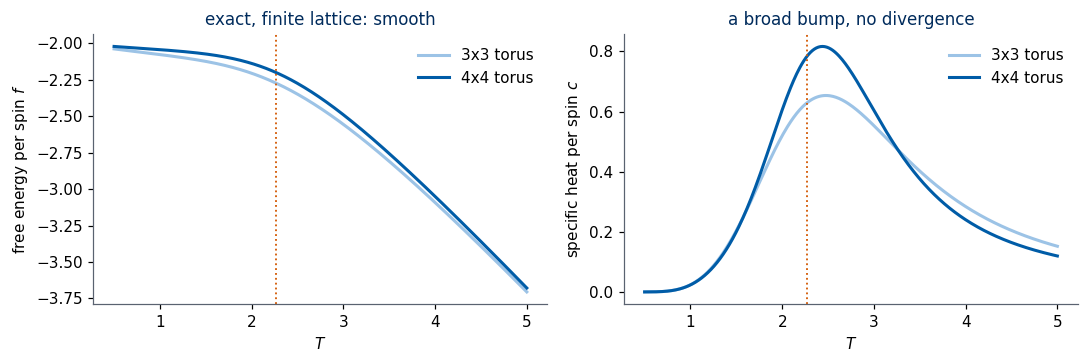

In [4]:
def thermo_from_dos(nb, N, T):
    # ln Z / N, u and c per spin from the histogram n_b of broken bonds
    T = np.atleast_1d(T)[:, None]
    Eb = -2 * N + 2 * np.arange(len(nb))
    logw = np.log(np.where(nb > 0, nb, 1)) - Eb / T
    logw = np.where(nb > 0, logw, -np.inf)
    shift = logw.max(axis=1, keepdims=True)                  # avoid overflow
    w = np.exp(logw - shift); Zr = w.sum(axis=1, keepdims=True); p = w / Zr
    E1 = (p * Eb).sum(1); E2 = (p * Eb**2).sum(1)
    lnZ = (np.log(Zr) + shift)[:, 0]
    return lnZ / N, E1 / N, (E2 - E1**2) / (N * T[:, 0]**2)

T = np.linspace(0.5, 5.0, 400)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for L, col in [(3, "#9CC3E6"), (4, UJBlue)]:
    lnz, u, c = thermo_from_dos(dos[L], L * L, T)
    ax[0].plot(T, -T * lnz, color=col, lw=2, label=f"{L}x{L} torus")
    ax[1].plot(T, c, color=col, lw=2, label=f"{L}x{L} torus")
    print(f"L = {L}: specific-heat maximum c = {c.max():.3f} at T = {T[c.argmax()]:.3f}")
for a in ax:
    a.axvline(TC, color=DSOrange, ls=":", lw=1.2); a.set_xlabel("$T$"); a.legend(frameon=False)
ax[0].set_ylabel("free energy per spin $f$"); ax[1].set_ylabel("specific heat per spin $c$")
ax[0].set_title("exact, finite lattice: smooth"); ax[1].set_title("a broad bump, no divergence")
plt.tight_layout(); plt.show()

In [5]:
# check: c from the energy variance equals the numerical derivative du/dT (4x4 torus)
T_chk, h_T = np.array([1.5, 2.0, 2.5, 3.0]), 1e-5
_, u_plus, _ = thermo_from_dos(dos[4], 16, T_chk + h_T)
_, u_minus, _ = thermo_from_dos(dos[4], 16, T_chk - h_T)
_, _, c_var = thermo_from_dos(dos[4], 16, T_chk)
for Tv, a, b_ in zip(T_chk, c_var, (u_plus - u_minus) / (2 * h_T)):
    print(f"T = {Tv:.1f}:  c = Var(E)/(N T^2) = {a:.8f}   c = du/dT (central difference) = {b_:.8f}")

T = 1.5:  c = Var(E)/(N T^2) = 0.20034987   c = du/dT (central difference) = 0.20034987
T = 2.0:  c = Var(E)/(N T^2) = 0.60553266   c = du/dT (central difference) = 0.60553266
T = 2.5:  c = Var(E)/(N T^2) = 0.81251523   c = du/dT (central difference) = 0.81251523
T = 3.0:  c = Var(E)/(N T^2) = 0.60313471   c = du/dT (central difference) = 0.60313471


The free energy is smooth, and the specific heat has a broad bump instead of a singularity, exactly as the analyticity argument demands for finite $N$.
The maximum of $c$ for the $4\times4$ torus lies at $T = 2.440$, near but not at $T_c$ (dotted line), and it is higher than that of the $3\times3$ torus.
Brute force cannot take us much further: $L = 6$ already has $2^{36}\approx 6.9\times10^{10}$ configurations, and the $20\times20$ images of Lab 010 have
$2^{400}\approx2.6\times10^{120}$. We need a way to perform the sum without listing the configurations. That way is the **transfer matrix**, which we first
introduce on the 1D chain, where every step can be carried out explicitly.

<hr/>
## 2. The 1D chain and the transfer matrix

The 1D chain is the simplest place to learn the transfer-matrix method that Onsager used in 2D. It also provides a reference point: we shall find that the chain
has *no* phase transition, which is what makes the 2D result remarkable.

Place $N$ spins on a ring, $s_{N+1}\equiv s_1$, with coupling $J=1$ and field $h$:
$$
H = -\sum_{i=1}^N s_is_{i+1} - h\sum_{i=1}^N s_i ,\qquad K = \beta,\quad \tilde h = \beta h .
$$
The first idea is to write the Boltzmann weight as a product of factors, one per bond. Every site belongs to two bonds, so we can give half of its field term to each:
$$
\begin{aligned}
-\beta H &= \sum_{i=1}^N\Big[Ks_is_{i+1} + \tfrac{\tilde h}{2}(s_i+s_{i+1})\Big]\\
\Rightarrow\quad e^{-\beta H} &= \prod_{i=1}^N \mathsf T_{s_is_{i+1}},\qquad
\mathsf T_{ss'} = e^{Kss' + \frac{\tilde h}{2}(s+s')} .
\end{aligned}
$$
Here $\mathsf T_{ss'}$ is the Boltzmann weight of one bond. Labelling rows and columns by $s=+1$ (first) and $s=-1$ (second), it is the matrix
$$
\mathsf T = \begin{pmatrix} e^{K+\tilde h} & e^{-K}\\ e^{-K} & e^{K-\tilde h}\end{pmatrix}.
$$

The sketch below draws a ring of $N=8$ spins. Every bond carries one factor $\mathsf T_{s_is_{i+1}}$, and the $2\times2$ table on the right lists the four possible values of this factor, one for each pair of neighbouring spins. The Boltzmann weight of the whole ring is the product of the eight bond factors, and closing the ring turns the sum over all spins into the trace of a matrix power, as we now show.

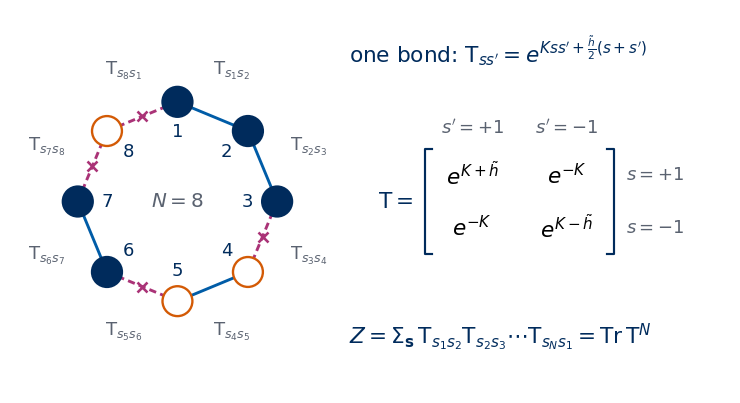

In [ ]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("figures", exist_ok=True)
    for d in ("figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def draw_spin(ax, x, y, s, r=0.26, sign=False, alpha=1.0, fs=10, lw=1.3):
    # one Ising spin at (x, y): navy disc for s = +1, white disc with orange rim for s = -1 (optionally with "+" / "-")
    face, edge, txt = (NAVY, NAVY, "white") if s > 0 else ("white", ORANGE, ORANGE)
    ax.add_patch(mpatches.Circle((x, y), r, fc=face, ec=edge, lw=lw, alpha=alpha, zorder=4))
    if sign:
        ax.text(x, y, "+" if s > 0 else "−", color=txt, ha="center", va="center", alpha=alpha,
                fontsize=fs, fontweight="bold", zorder=5)

def draw_bond(ax, p, q, broken=False, lw=1.5, alpha=1.0, color=None, cross=True):
    # bond between points p and q: solid blue if satisfied, dashed purple with a cross if broken
    c = color or (PURPLE if broken else BLUE)
    ax.plot([p[0], q[0]], [p[1], q[1]], color=c, lw=lw, ls=(0, (2.5, 1.5)) if broken else "-",
            alpha=alpha, solid_capstyle="round", zorder=2)
    if broken and cross:
        ax.plot((p[0] + q[0]) / 2, (p[1] + q[1]) / 2, marker="x", ms=3.5 * lw, mew=lw * 0.9, color=c, alpha=alpha, zorder=3)

def sketch_ising_ring():
    N = 8
    s = np.array([1, 1, 1, -1, -1, 1, 1, -1])                      # an arbitrary configuration of the ring
    phi = np.pi / 2 - 2 * np.pi * np.arange(N) / N                  # site i at angle phi_i, clockwise from the top
    R = 2.0
    X, Y = R * np.cos(phi), R * np.sin(phi)
    fig = plt.figure(figsize=(5.5, 2.9))
    ax = fig.add_axes([0.0, 0.0, 0.46, 1.0]); tx = fig.add_axes([0.47, 0.0, 0.53, 1.0]); tx.axis("off")

    for i in range(N):
        j = (i + 1) % N                                             # s_{N+1} = s_1 closes the ring
        draw_bond(ax, (X[i], Y[i]), (X[j], Y[j]), broken=s[i] * s[j] < 0, lw=1.6)
        mid = phi[i] - np.pi / N                                    # angle of the bond midpoint
        ax.text(1.42 * R * np.cos(mid), 1.42 * R * np.sin(mid), rf"$\mathsf{{T}}_{{s_{i + 1}s_{j + 1}}}$",
                fontsize=10, ha="center", va="center", color=GRAY)
    for i in range(N):
        draw_spin(ax, X[i], Y[i], s[i], r=0.3)
        ax.text(0.7 * R * np.cos(phi[i]), 0.7 * R * np.sin(phi[i]), f"{i + 1}", fontsize=10, ha="center", va="center", color=NAVY)
    ax.text(0, 0, f"$N={N}$", ha="center", va="center", fontsize=11, color=GRAY)
    ax.set_xlim(-3.3, 3.3); ax.set_ylim(-3.3, 3.3); ax.set_aspect("equal"); ax.axis("off")

    # the transfer matrix: the Boltzmann weight of one bond, rows s = +1, -1 and columns s' = +1, -1
    tx.set_xlim(0, 1); tx.set_ylim(0, 1)
    tx.text(0.0, 0.9, r"one bond: $\mathsf{T}_{ss'}=e^{Kss'+\frac{\tilde h}{2}(s+s')}$", fontsize=12, color=NAVY, va="center")
    cells = [[r"$e^{K+\tilde h}$", r"$e^{-K}$"], [r"$e^{-K}$", r"$e^{K-\tilde h}$"]]
    x0, y0, w, h = 0.2, 0.36, 0.25, 0.14
    tx.text(x0 - 0.03, y0 + h, r"$\mathsf{T}=$", fontsize=12, color=NAVY, ha="right", va="center")
    for r_ in range(2):
        for c_ in range(2):
            tx.text(x0 + (c_ + 0.5) * w, y0 + (1.5 - r_) * h, cells[r_][c_], fontsize=12, ha="center", va="center")
    for xb, d in [(x0, 0.02), (x0 + 2 * w, -0.02)]:                 # square brackets around the 2 x 2 matrix
        tx.plot([xb + d, xb, xb, xb + d], [y0, y0, y0 + 2 * h, y0 + 2 * h], color=NAVY, lw=1.2)
    for lab, k in [("$s=+1$", 0), ("$s=-1$", 1)]:
        tx.text(x0 + 2 * w + 0.03, y0 + (1.5 - k) * h, lab, fontsize=10, color=GRAY, va="center")
    for lab, k in [("$s'=+1$", 0), ("$s'=-1$", 1)]:
        tx.text(x0 + (k + 0.5) * w, y0 + 2 * h + 0.04, lab, fontsize=10, color=GRAY, ha="center")
    tx.text(0.0, 0.14, r"$Z=\Sigma_{\mathbf{s}}\,\mathsf{T}_{s_1s_2}\mathsf{T}_{s_2s_3}\cdots\mathsf{T}_{s_Ns_1}=\mathrm{Tr}\,\mathsf{T}^N$",
            fontsize=12, color=NAVY, va="center")
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_ising_ring()
save_sketch(fig, "sketch_ising_chain.png")
plt.show()


The second idea is that summing over a spin is a matrix multiplication. The spin $s_2$ appears only in $\mathsf T_{s_1s_2}\mathsf T_{s_2s_3}$, and
$\sum_{s_2}\mathsf T_{s_1s_2}\mathsf T_{s_2s_3} = (\mathsf T^2)_{s_1s_3}$ is precisely the definition of the matrix product. Summing $s_2,\dots,s_N$ in turn and closing the ring we find
$$
\begin{aligned}
Z &= \sum_{s_1,\dots,s_N}\mathsf T_{s_1s_2}\mathsf T_{s_2s_3}\cdots\mathsf T_{s_Ns_1}\\
&= \sum_{s_1}(\mathsf T^N)_{s_1s_1} = \operatorname{Tr}\mathsf T^N ,
\end{aligned}
$$
so that a sum of $2^N$ terms has become $N-1$ multiplications of $2\times2$ matrices.

The trace of a matrix power is controlled by the eigenvalues. Since $\mathsf T$ is real symmetric, $\mathsf T = U\Lambda U^\top$ with $U$ orthogonal and
$\Lambda=\operatorname{diag}(\lambda_+,\lambda_-)$. Then $\mathsf T^N = U\Lambda^NU^\top$ and, because the trace is invariant under $U$,
$$
Z = \lambda_+^N + \lambda_-^N .
$$
The eigenvalues of a symmetric $2\times2$ matrix $\begin{pmatrix}a&b\\b&d\end{pmatrix}$ are $\frac{a+d}{2}\pm\sqrt{\left(\frac{a-d}{2}\right)^2+b^2}$, which gives
$$
\begin{aligned}
\lambda_\pm &= e^{K}\cosh\tilde h \pm \sqrt{e^{2K}\sinh^2\tilde h + e^{-2K}},\\
\text{at } h=0:\quad \lambda_\pm &= e^K\pm e^{-K},\ \text{i.e. } \lambda_+ = 2\cosh K,\ \lambda_- = 2\sinh K ,
\end{aligned}
$$
with eigenvectors $(1,1)/\sqrt2$ and $(1,-1)/\sqrt2$ at $h=0$.

A small case makes the result concrete. A ring of two spins ($N=2$, $h=0$) has two bonds between the same pair, so directly
$Z=\sum_{s_1,s_2}e^{2Ks_1s_2} = 2e^{2K}+2e^{-2K}=4\cosh2K$, while the formula gives $(2\cosh K)^2+(2\sinh K)^2 = 4(\cosh^2K+\sinh^2K) = 4\cosh 2K$, the same.

We now let SymPy repeat the derivation symbolically. It diagonalises $\mathsf T$, and we confirm the closed form of $\lambda_\pm$ by comparing the radicands,
then the values at $h=0$ and the $N=2$ example; every printed difference should be exactly zero. The following cell turns to numbers: for a ring of $N=14$
spins it compares $\operatorname{Tr}\mathsf T^N$ with the brute-force sum over all $2^{14}$ configurations, with and without a field, and compares the closed form of
$\lambda_\pm$ with the eigenvalues returned by `numpy`.

In [6]:
K, ht = sp.symbols("K htilde", positive=True)
T_sym = sp.Matrix([[sp.exp(K + ht), sp.exp(-K)], [sp.exp(-K), sp.exp(K - ht)]])
display(sp.Eq(sp.Symbol(r"\mathsf{T}"), T_sym, evaluate=False))
a, b_, d = T_sym[0, 0], T_sym[0, 1], T_sym[1, 1]
radicand_matrix = ((a - d) / 2)**2 + b_**2                                   # eigenvalues: (a+d)/2 +- sqrt(radicand)
radicand_formula = sp.exp(2 * K) * sp.sinh(ht)**2 + sp.exp(-2 * K)
print("(a+d)/2 - e^K cosh(h~)                      =", sp.simplify(((a + d) / 2 - sp.exp(K) * sp.cosh(ht)).rewrite(sp.exp)))
print("radicand - (e^{2K} sinh^2 h~ + e^{-2K})      =", sp.simplify((radicand_matrix - radicand_formula).rewrite(sp.exp)))
lam_h0 = [sp.simplify(sp.Rational(1, 2) * (2 * sp.exp(K)) + s * sp.sqrt(sp.exp(-2 * K))) for s in (1, -1)]
print("lambda_+ - 2 cosh K at h = 0                 =", sp.simplify((lam_h0[0] - 2 * sp.cosh(K)).rewrite(sp.exp)))
print("lambda_- - 2 sinh K at h = 0                 =", sp.simplify((lam_h0[1] - 2 * sp.sinh(K)).rewrite(sp.exp)))
print("eigenvalues of T(h=0) from SymPy             :", [sp.simplify(e.rewrite(sp.cosh)) for e in T_sym.subs(ht, 0).eigenvals()])
print("N = 2 example: Tr T^2 - 4 cosh 2K            =", sp.simplify(((T_sym.subs(ht, 0)**2).trace() - 4 * sp.cosh(2 * K)).rewrite(sp.exp)))

Eq(\mathsf{T}, Matrix([
[exp(K + htilde),         exp(-K)],
[        exp(-K), exp(K - htilde)]]))

(a+d)/2 - e^K cosh(h~)                      = 0
radicand - (e^{2K} sinh^2 h~ + e^{-2K})      = 0
lambda_+ - 2 cosh K at h = 0                 = 0
lambda_- - 2 sinh K at h = 0                 = 0
eigenvalues of T(h=0) from SymPy             : [2*cosh(K), 2*sinh(K)]
N = 2 example: Tr T^2 - 4 cosh 2K            = 0


In [7]:
def Z_chain_brute(N, K, ht):
    S = all_configs(N).astype(float)
    E_over_T = -K * (S * np.roll(S, -1, axis=1)).sum(1) - ht * S.sum(1)     # beta*H
    return np.exp(-E_over_T).sum()

def T_chain(K, ht):
    return np.array([[np.exp(K + ht), np.exp(-K)], [np.exp(-K), np.exp(K - ht)]])

N = 14
for K, ht in [(0.3, 0.0), (1.0, 0.0), (0.7, 0.4), (1.5, -0.2)]:
    Zb = Z_chain_brute(N, K, ht)
    Zt = np.trace(np.linalg.matrix_power(T_chain(K, ht), N))
    lam_num = np.sort(np.linalg.eigvalsh(T_chain(K, ht)))[::-1]
    root = np.sqrt(np.exp(2 * K) * np.sinh(ht)**2 + np.exp(-2 * K))
    lam_exact = np.array([np.exp(K) * np.cosh(ht) + root, np.exp(K) * np.cosh(ht) - root])
    print(f"K={K:3.1f}, beta*h={ht:4.1f}:  Z brute = {Zb:.10e}   Tr T^N = {Zt:.10e}   "
          f"max|lambda_numpy - lambda_formula| = {np.abs(lam_num - lam_exact).max():.1e}")

K=0.3, beta*h= 0.0:  Z brute = 3.0480162419e+04   Tr T^N = 3.0480162419e+04   max|lambda_numpy - lambda_formula| = 1.1e-16


K=1.0, beta*h= 0.0:  Z brute = 7.2668862529e+06   Tr T^N = 7.2668862529e+06   max|lambda_numpy - lambda_formula| = 0.0e+00
K=0.7, beta*h= 0.4:  Z brute = 9.1298799858e+06   Tr T^N = 9.1298799858e+06   max|lambda_numpy - lambda_formula| = 8.9e-16
K=1.5, beta*h=-0.2:  Z brute = 2.3316896955e+10   Tr T^N = 2.3316896955e+10   max|lambda_numpy - lambda_formula| = 4.4e-16


The two partition functions agree to all printed digits, and the eigenvalue formula agrees with `numpy` to rounding error, so we may now use the eigenvalues
to take the limit of a long chain.

### 2.1 Free energy and correlation length of the chain

Factor out the larger eigenvalue: $\ln Z = N\ln\lambda_+ + \ln\big(1 + r^N\big)$ with $r=\lambda_-/\lambda_+ = \tanh K<1$.
The second term tends to $0$, so for $N\to\infty$ only the largest eigenvalue survives:
$$
\begin{aligned}
-\beta f &= \ln\lambda_+ = \ln\big(2\cosh K\big),\\
u &= \frac{\partial(\beta f)}{\partial\beta} = -\tanh K,\\
c &= \frac{\partial u}{\partial T} = \frac{K^2}{\cosh^2K}.
\end{aligned}
$$
These are compositions of analytic functions with $2\cosh K>0$, so $f$ is analytic at every $T>0$: **the 1D chain has no phase transition** [Ising 1925].
Its specific heat is a single smooth bump that does not depend on $N$.

The transfer matrix also tells us how strongly spin $s_0$ influences spin $s_r$. The product $s_0s_r$ inserts the diagonal matrix
$\sigma^z = \operatorname{diag}(1,-1)$ at the two positions:
$$
\langle s_0s_r\rangle = \frac{\operatorname{Tr}\big(\sigma^z\mathsf T^r\sigma^z\mathsf T^{N-r}\big)}{\operatorname{Tr}\mathsf T^N}.
$$
Write $\mathsf T = \lambda_+|{+}\rangle\langle{+}| + \lambda_-|{-}\rangle\langle{-}|$ with the eigenvectors $|{\pm}\rangle = (1,\pm1)/\sqrt2$.
For $N\to\infty$, $\mathsf T^{N-r}\approx\lambda_+^{N-r}|{+}\rangle\langle{+}|$, and $\sigma^z$ maps $|{+}\rangle$ to $|{-}\rangle$. Hence
$$
\begin{aligned}
\langle s_0s_r\rangle &\to \frac{\lambda_+^{N-r}\,\langle{-}|\mathsf T^r|{-}\rangle}{\lambda_+^N} = \Big(\frac{\lambda_-}{\lambda_+}\Big)^r\\
&= (\tanh K)^r = e^{-r/\xi},\\
\xi &= \frac{1}{\ln(\lambda_+/\lambda_-)} = -\frac{1}{\ln\tanh K}.
\end{aligned}
$$
The quantity $\xi$ is the **correlation length**, the distance over which a spin "remembers" the orientation of another, and it is finite at every $T>0$.

The same result can be seen without matrices. At $h=0$ the bond variables $\tau_i = s_is_{i+1}$ of an open chain are independent, each bond being broken ($\tau_i=-1$)
with probability $p = e^{-K}/(e^K+e^{-K})$. Since $s_0s_r = \tau_0\tau_1\cdots\tau_{r-1}$, we get $\langle s_0s_r\rangle = \langle\tau\rangle^r = (1-2p)^r = (\tanh K)^r$.
Each broken bond, a *domain wall*, flips the sign of the correlation. At low $T$, $p\approx e^{-2K}$ and $\xi\approx \frac12e^{2K}$:
the walls are rare but never absent, and $\xi$ diverges only at $T=0$.

The next three cells confirm these statements. SymPy differentiates $\ln(2\cosh K)$ to obtain $u$ and $c$, and a finite difference of $\ln\lambda_{\max}$ reproduces
$u=-\tanh K$. Then the correlation function is computed from the trace formula for a ring of 400 spins and compared with $(\tanh K)^r$; the differences are at the level of
rounding errors, and the correlation length grows from $\xi = 1.295$ at $K=0.5$ to $\xi = 10.034$ at $K=1.5$. Finally we locate the maximum of the 1D specific heat and
compare $\xi$ with its low-temperature form $\frac12e^{2K}$, which becomes accurate as $K$ grows.

In [8]:
# SymPy: f, u, c and the eigenvalue ratio of the infinite chain (h = 0)
K, Tt = sp.symbols("K T", positive=True)
minus_beta_f = sp.log(2 * sp.cosh(K))
u_sym = -sp.diff(minus_beta_f, K)                              # u = d(beta f)/d beta, beta = K for J = 1
c_sym = sp.simplify(sp.diff(u_sym.subs(K, 1 / Tt), Tt).subs(Tt, 1 / K))
display(sp.Eq(sp.Symbol("u"), sp.simplify(u_sym)), sp.Eq(sp.Symbol("c"), c_sym),
        sp.Eq(sp.Symbol(r"\lambda_-/\lambda_+"), sp.simplify(sp.sinh(K) / sp.cosh(K))))
# numerical check: u from a finite difference of ln(lambda_+) of the numerical matrix
for Kv in (0.5, 1.0, 2.0):
    lnlam = lambda k: np.log(np.max(np.linalg.eigvalsh(T_chain(k, 0.0))))
    u_fd = -(lnlam(Kv + 1e-6) - lnlam(Kv - 1e-6)) / 2e-6
    print(f"K = {Kv}: u (finite difference of ln lambda_max) = {u_fd:.8f},  -tanh K = {-np.tanh(Kv):.8f}")

Eq(u, -tanh(K))

Eq(c, K**2/cosh(K)**2)

Eq(\lambda_-/\lambda_+, tanh(K))

K = 0.5: u (finite difference of ln lambda_max) = -0.46211716,  -tanh K = -0.46211716
K = 1.0: u (finite difference of ln lambda_max) = -0.76159416,  -tanh K = -0.76159416
K = 2.0: u (finite difference of ln lambda_max) = -0.96402758,  -tanh K = -0.96402758


K = 0.5: max |<s0 sr> - tanh(K)^r| over r<25 = 7.1e-17,  xi = 1.295
K = 1.0: max |<s0 sr> - tanh(K)^r| over r<25 = 1.1e-16,  xi = 3.672
K = 1.5: max |<s0 sr> - tanh(K)^r| over r<25 = 4.4e-16,  xi = 10.034


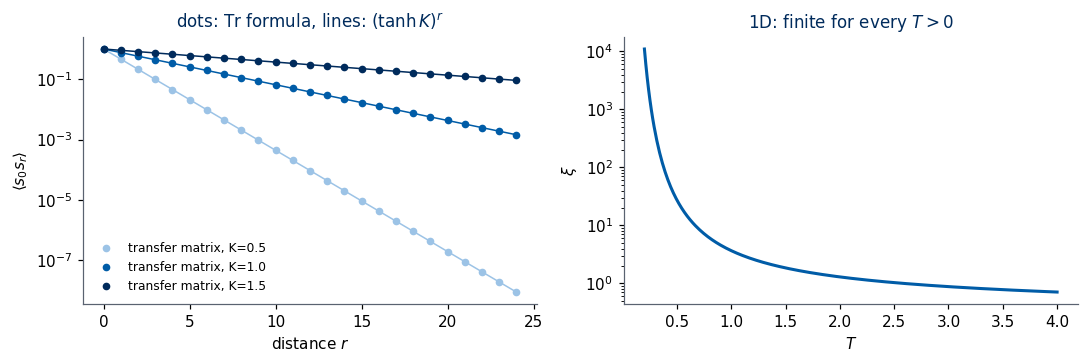

In [9]:
sz = np.diag([1.0, -1.0])
N, r = 400, np.arange(0, 25)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for K, col in [(0.5, "#9CC3E6"), (1.0, UJBlue), (1.5, UJNavy)]:
    Tm = T_chain(K, 0.0) / (2 * np.cosh(K))                 # rescaled, to avoid overflow; ratios are unchanged
    corr = [np.trace(sz @ np.linalg.matrix_power(Tm, k) @ sz @ np.linalg.matrix_power(Tm, N - k)) /
            np.trace(np.linalg.matrix_power(Tm, N)) for k in r]
    ax[0].semilogy(r, corr, "o", color=col, ms=4, label=f"transfer matrix, K={K}")
    ax[0].semilogy(r, np.tanh(K)**r, "-", color=col, lw=1)
    print(f"K = {K}: max |<s0 sr> - tanh(K)^r| over r<25 = {np.max(np.abs(np.array(corr) - np.tanh(K)**r)):.1e},"
          f"  xi = {-1/np.log(np.tanh(K)):.3f}")
ax[0].set_xlabel("distance $r$"); ax[0].set_ylabel(r"$\langle s_0 s_r\rangle$"); ax[0].legend(frameon=False, fontsize=8)
ax[0].set_title(r"dots: $\mathrm{Tr}$ formula, lines: $(\tanh K)^r$")
Tg = np.linspace(0.2, 4, 300)
ax[1].plot(Tg, -1 / np.log(np.tanh(1 / Tg)), color=UJBlue, lw=2)
ax[1].set_yscale("log"); ax[1].set_xlabel("$T$"); ax[1].set_ylabel(r"$\xi$"); ax[1].set_title("1D: finite for every $T>0$")
plt.tight_layout(); plt.show()

In [10]:
# the 1D chain: specific heat bump, broken-bond probability and the low-T form of xi
Kv = np.linspace(0.05, 10, 200001)
c1d = Kv**2 / np.cosh(Kv)**2
print(f"1D specific heat c = K^2/cosh^2 K: maximum {c1d.max():.4f} at T = {1/Kv[c1d.argmax()]:.4f} (independent of N)")
for K in (0.5, 1.0, 2.0, 3.0, 4.0):
    p_br = np.exp(-K) / (2 * np.cosh(K))
    xi1 = -1 / np.log(np.tanh(K))
    print(f"K = {K}:  1 - 2p = {1 - 2*p_br:.10f}, tanh K = {np.tanh(K):.10f};   xi = {xi1:10.4f},  e^(2K)/2 = {np.exp(2*K)/2:10.4f}")

1D specific heat c = K^2/cosh^2 K: maximum 0.4392 at T = 0.8336 (independent of N)
K = 0.5:  1 - 2p = 0.4621171573, tanh K = 0.4621171573;   xi =     1.2954,  e^(2K)/2 =     1.3591
K = 1.0:  1 - 2p = 0.7615941560, tanh K = 0.7615941560;   xi =     3.6719,  e^(2K)/2 =     3.6945
K = 2.0:  1 - 2p = 0.9640275801, tanh K = 0.9640275801;   xi =    27.2960,  e^(2K)/2 =    27.2991
K = 3.0:  1 - 2p = 0.9950547537, tanh K = 0.9950547537;   xi =   201.7140,  e^(2K)/2 =   201.7144
K = 4.0:  1 - 2p = 0.9993292997, tanh K = 0.9993292997;   xi =  1490.4789,  e^(2K)/2 =  1490.4790


The 1D chain thus teaches two lessons that carry over to 2D unchanged. For $N\to\infty$ only the largest eigenvalue matters, $\ln Z \approx N\ln\lambda_{\max}$,
and the correlation length is set by the ratio of the two largest eigenvalues, $\xi = 1/\ln(\lambda_{\max}/\lambda_2)$. What changes in 2D is the size of the matrix.
A phase transition would require $\lambda_2/\lambda_{\max}\to1$, so that $\xi\to\infty$, at some $T>0$, and a $2\times2$ matrix with positive entries never allows this:
by the Perron–Frobenius theorem its largest eigenvalue is strictly larger than the other in absolute value.

<hr/>
## 3. The transfer matrix in two dimensions

The 1D method extends to 2D once we let a whole *column* of spins play the role of a single spin. The price is the size of the matrix, $2^L\times2^L$.
For small widths $L$ we can still diagonalise it numerically. This gives exact results for infinitely long strips, shows how a transition builds up as $L$ grows,
and sets the stage for Onsager, who found the largest eigenvalue for every $L$ analytically.

Consider a strip of $L$ rows, periodic in the vertical direction ($s_{L+1}\equiv s_1$), and $L'$ columns, also periodic, with $L'\to\infty$ at the end.
A column $\sigma = (s_1,\dots,s_L)$ has $2^L$ states. The energy splits into bonds *inside* a column (vertical) and bonds *between* neighbouring columns (horizontal):
$$
-\beta H = \sum_{j=1}^{L'}\Big[K\sum_{i=1}^L s_i^{(j)}s_i^{(j+1)} + K\sum_{i=1}^L s_i^{(j)}s_{i+1}^{(j)}\Big],
$$
where $s_i^{(j)}$ is the spin in row $i$ of column $j$. Giving half of each column's internal energy to the factor on its left and half to the one on its right, we obtain
$$
\begin{aligned}
Z &= \sum_{\sigma_1,\dots,\sigma_{L'}}\mathsf V_{\sigma_1\sigma_2}\mathsf V_{\sigma_2\sigma_3}\cdots\mathsf V_{\sigma_{L'}\sigma_1} = \operatorname{Tr}\mathsf V^{L'},\\
\mathsf V_{\sigma\sigma'} &= \exp\Big[K\sum_{i=1}^L s_is_i' + \frac K2\sum_{i=1}^L\big(s_is_{i+1} + s'_is'_{i+1}\big)\Big].
\end{aligned}
$$
An element $\mathsf V_{\sigma\sigma'}$ is the Boltzmann weight of placing column $\sigma'$ to the right of column $\sigma$: it contains the $L$ horizontal bonds
between them and half of the vertical bonds of each. The half-and-half split makes $\mathsf V$ symmetric, $\mathsf V_{\sigma\sigma'}=\mathsf V_{\sigma'\sigma}$.

The sketch below shows a strip of $L=4$ rows. The two framed columns are the states $\sigma$ and $\sigma'$ of neighbouring columns. The matrix element $\mathsf V_{\sigma\sigma'}$ collects the $L$ horizontal bonds between them (blue) and half of the vertical bonds inside each of them (green). The dashed vertical bonds lead to the faded copy of row 1 and close each column periodically. Multiplying $\mathsf V$ from column to column and closing the strip in the horizontal direction gives $Z=\operatorname{Tr}\mathsf V^{L'}$, just as for the ring.

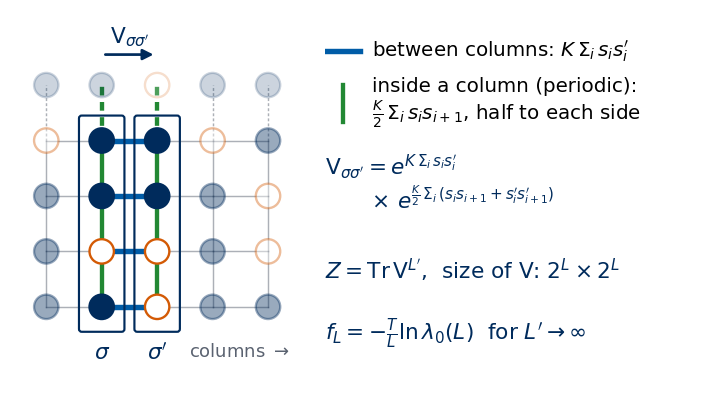

In [ ]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("figures", exist_ok=True)
    for d in ("figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def draw_spin(ax, x, y, s, r=0.26, sign=False, alpha=1.0, fs=10, lw=1.3):
    # one Ising spin at (x, y): navy disc for s = +1, white disc with orange rim for s = -1 (optionally with "+" / "-")
    face, edge, txt = (NAVY, NAVY, "white") if s > 0 else ("white", ORANGE, ORANGE)
    ax.add_patch(mpatches.Circle((x, y), r, fc=face, ec=edge, lw=lw, alpha=alpha, zorder=4))
    if sign:
        ax.text(x, y, "+" if s > 0 else "−", color=txt, ha="center", va="center", alpha=alpha,
                fontsize=fs, fontweight="bold", zorder=5)

def draw_bond(ax, p, q, broken=False, lw=1.5, alpha=1.0, color=None, cross=True):
    # bond between points p and q: solid blue if satisfied, dashed purple with a cross if broken
    c = color or (PURPLE if broken else BLUE)
    ax.plot([p[0], q[0]], [p[1], q[1]], color=c, lw=lw, ls=(0, (2.5, 1.5)) if broken else "-",
            alpha=alpha, solid_capstyle="round", zorder=2)
    if broken and cross:
        ax.plot((p[0] + q[0]) / 2, (p[1] + q[1]) / 2, marker="x", ms=3.5 * lw, mew=lw * 0.9, color=c, alpha=alpha, zorder=3)

def sketch_column_transfer_matrix():
    L, ncol = 4, 5                                                  # strip of L rows; ncol columns are drawn
    S = np.array([[ 1,  1, -1,  1,  1],
                  [ 1, -1, -1,  1, -1],
                  [ 1,  1,  1,  1, -1],
                  [-1,  1,  1, -1,  1]])                            # S[row i, column j]
    j0 = 1                                                          # the pair of columns (j0, j0 + 1) is highlighted
    fig = plt.figure(figsize=(5.5, 2.9))
    ax = fig.add_axes([0.0, 0.0, 0.45, 1.0]); tx = fig.add_axes([0.46, 0.0, 0.54, 1.0]); tx.axis("off")

    for j in range(ncol):
        hot = j in (j0, j0 + 1)
        for i in range(L):
            if j + 1 < ncol:                                        # horizontal bond between columns j and j + 1
                between = j == j0
                ax.plot([j, j + 1], [i, i], color=BLUE if between else GRAY, lw=3 if between else 0.8, alpha=1 if between else 0.5, zorder=1)
            # vertical bond inside column j; the bond from row L to the copy of row 1 closes the periodic column
            ax.plot([j, j], [i, i + 1], color=GREEN if hot else GRAY, lw=2.4 if hot else 0.8, alpha=1 if hot else 0.5,
                    ls="-" if i + 1 < L else (0, (2, 1.5)), zorder=1)
            draw_spin(ax, j, i, S[i, j], r=0.22, alpha=1 if hot else 0.4)
        draw_spin(ax, j, L, S[0, j], r=0.22, alpha=0.2)             # copy of row 1 (periodic in the vertical)
    for j, lab in [(j0, r"$\sigma$"), (j0 + 1, r"$\sigma'$")]:
        ax.add_patch(mpatches.FancyBboxPatch((j - 0.36, -0.4), 0.72, L - 0.2, boxstyle="round,pad=0.05", fc="none", ec=NAVY, lw=1.2))
        ax.text(j, -0.65, lab, ha="center", va="top", fontsize=12, color=NAVY)
    ax.annotate("", xy=(j0 + 1, L + 0.55), xytext=(j0, L + 0.55), arrowprops=dict(arrowstyle="-|>", color=NAVY, lw=1.5, mutation_scale=12))
    ax.text(j0 + 0.5, L + 0.75, r"$\mathsf{V}_{\sigma\sigma'}$", ha="center", fontsize=12, color=NAVY)
    ax.text(ncol - 0.6, -0.65, r"columns $\rightarrow$", ha="right", va="top", fontsize=10, color=GRAY)
    ax.set_xlim(-0.6, ncol - 0.4); ax.set_ylim(-1.5, L + 1.3); ax.set_aspect("equal"); ax.axis("off")

    tx.set_xlim(0, 1); tx.set_ylim(0, 1)
    tx.plot([0.0, 0.09], [0.9, 0.9], color=BLUE, lw=3)
    tx.text(0.12, 0.9, r"between columns: $K\,\Sigma_i\,s_i s_i'$", fontsize=11, va="center")
    tx.plot([0.045, 0.045], [0.71, 0.81], color=GREEN, lw=2.4)
    tx.text(0.12, 0.76, r"inside a column (periodic):" "\n" r"$\frac{K}{2}\,\Sigma_i\,s_i s_{i+1}$, half to each side", fontsize=11, va="center")
    tx.text(0.0, 0.55, r"$\mathsf{V}_{\sigma\sigma'}=e^{K\,\Sigma_i\,s_is_i'}$" "\n"
            r"$\qquad\times\,e^{\frac{K}{2}\,\Sigma_i\,(s_is_{i+1}+s_i's_{i+1}')}$", fontsize=12, color=NAVY, va="center")
    tx.text(0.0, 0.32, r"$Z=\mathrm{Tr}\,\mathsf{V}^{L'}$,  size of $\mathsf{V}$: $2^L\times 2^L$", fontsize=12, color=NAVY, va="center")
    tx.text(0.0, 0.15, r"$f_L=-\frac{T}{L}\ln\lambda_0(L)$  for $L'\to\infty$", fontsize=12, color=NAVY, va="center")
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_column_transfer_matrix()
save_sketch(fig, "sketch_ising_transfer_matrix.png")
plt.show()


For example, take $L=2$. Two rows on a periodic column are joined by two vertical bonds, so $\sum_is_is_{i+1}=2s_1s_2$. For $\sigma=\sigma'=(+,+)$ we find
$\mathsf V = \exp[2K + \tfrac K2(2+2)] = e^{4K}$, and for $\sigma=(+,+)$, $\sigma'=(-,-)$ we find $\mathsf V = \exp[-2K + 2K] = 1$.

As in 1D, $Z=\sum_k\lambda_k^{L'}$ over the eigenvalues of $\mathsf V$. All entries of $\mathsf V$ are positive, so by the Perron–Frobenius theorem the largest eigenvalue
$\lambda_0$ is positive, non-degenerate, and strictly larger than all others in absolute value. For $L'\to\infty$, $\ln Z \approx L'\ln\lambda_0$, and dividing by the
number of spins $LL'$ gives the free energy and correlation length of the strip,
$$
f_L(T) = -\frac{T}{L}\ln\lambda_0(L),\qquad \xi_L = \frac{1}{\ln(\lambda_0/\lambda_1)},
$$
where $\xi_L$ is the correlation length along the strip and $\lambda_1$ is the largest eigenvalue that couples to a single spin, defined precisely below.
Onsager's free energy is $f = \lim_{L\to\infty}f_L$. The cost is that $\mathsf V$ has $4^L$ entries: $L=12$ needs $1.7\times10^7$ numbers, and $L=50$ would need $10^{30}$.

The global spin flip helps to organise the spectrum. Flipping all spins, $\sigma\to-\sigma$, does not change $\mathsf V$; in our bit encoding the flip maps the index
$n\to \bar n = 2^L-1-n$. Vectors with $v_{\bar n}=v_n$ (even) and with $v_{\bar n}=-v_n$ (odd) are mapped by $\mathsf V$ into vectors of the same type, so $\mathsf V$
splits into an even block ($\mathsf V_{nm}+\mathsf V_{n\bar m}$) and an odd block ($\mathsf V_{nm}-\mathsf V_{n\bar m}$), each of size $2^{L-1}$, with $n,m<2^{L-1}$.
The eigenvalue $\lambda_0$, whose eigenvector is positive, is the top of the even block. A single spin $s_i$ changes sign under the flip, so it connects the even sector to
the odd one, and the correlation $\langle s_i^{(0)}s_i^{(r)}\rangle$ decays as $(\lambda_1/\lambda_0)^r$ with $\lambda_1$ the top of the odd block — exactly as $\lambda_-$ did in 1D.

Before trusting the construction we test it where the answer is known. On an $L\times L'$ torus $Z = \operatorname{Tr}\mathsf V^{L'}$ holds exactly, so for $4\times4$ the
trace must reproduce the brute-force histogram of Section 1 at every temperature; the cell after it checks the two matrix elements of the $L=2$ example and the symmetry of $\mathsf V$.

In [11]:
def transfer_matrix(L, K, lattice="square"):
    # V[sigma, sigma'] for a periodic column of L spins; 'triangular' adds the diagonal bonds s_i s'_{i+1} (Section 10)
    S = all_configs(L).astype(float)
    intra = (S * np.roll(S, -1, axis=1)).sum(1)                 # sum_i s_i s_{i+1} inside a column
    inter = S @ S.T                                             # sum_i s_i s'_i
    if lattice == "triangular":
        inter = inter + S @ np.roll(S, -1, axis=1).T            # sum_i s_i s'_{i+1}
    return np.exp(K * (inter + 0.5 * (intra[:, None] + intra[None, :])))

def top_eigenvalue(A, symmetric):
    n = A.shape[0]
    if symmetric and n <= 64:
        return eigh(A, eigvals_only=True, subset_by_index=[n - 1, n - 1])[0]
    if symmetric:
        return eigsh(A, k=1, which="LA", tol=0)[0][0]           # Lanczos: only the top eigenvalue
    if n <= 64:
        return np.max(np.linalg.eigvals(A).real)
    return eigs(A, k=1, which="LR", tol=1e-14)[0][0].real

def lambda01(L, K, lattice="square"):
    # (lambda_0, lambda_1): largest eigenvalues in the spin-flip even and odd sectors
    V = transfer_matrix(L, K, lattice)
    n = V.shape[0] // 2
    Vflip = V[:, ::-1]                                          # column m -> its flipped partner 2^L-1-m
    sym = lattice == "square"
    return (top_eigenvalue(V[:n, :n] + Vflip[:n, :n], sym),
            top_eigenvalue(V[:n, :n] - Vflip[:n, :n], sym))

# check: Z of the 4x4 torus from Tr V^4 versus the brute-force histogram
for T in (1.5, TC, 3.5):
    V = transfer_matrix(4, 1 / T)
    Z_tm = np.trace(np.linalg.matrix_power(V, 4))
    lnz_dos, _, _ = thermo_from_dos(dos[4], 16, T)
    print(f"T = {T:.4f}:  ln Z (Tr V^4) = {np.log(Z_tm):.12f}   ln Z (brute force) = {16 * lnz_dos[0]:.12f}")

T = 1.5000:  ln Z (Tr V^4) = 22.117013911716   ln Z (brute force) = 22.117013911716
T = 2.2692:  ln Z (Tr V^4) = 15.521915458755   ln Z (brute force) = 15.521915458755
T = 3.5000:  ln Z (Tr V^4) = 12.600438025330   ln Z (brute force) = 12.600438025330


In [12]:
# example L = 2: index 0 = (+,+), index 3 = (-,-)
K = 0.3
V2 = transfer_matrix(2, K)
print(f"V[(+,+),(+,+)] = {V2[0, 0]:.10f}   e^(4K) = {np.exp(4*K):.10f}")
print(f"V[(+,+),(-,-)] = {V2[0, 3]:.10f}   expected 1")
print(f"V symmetric: max |V - V^T| = {np.abs(V2 - V2.T).max():.1e}")

V[(+,+),(+,+)] = 3.3201169227   e^(4K) = 3.3201169227
V[(+,+),(-,-)] = 1.0000000000   expected 1
V symmetric: max |V - V^T| = 0.0e+00


Both tests pass to all printed digits. We can now use the strips to approach the infinite plane.

### 3.1 Free energy and specific heat of strips
We scan the temperature for strips of width $L=4,6,8,10$. The specific heat $c_L = -T\,\partial^2 f_L/\partial T^2$, which follows from $u=\partial(\beta f)/\partial\beta$ and
$c=\partial u/\partial T$, is computed by finite differences on a fine grid; since the eigenvalues are accurate to machine precision, the second difference is reliable.
Onsager's $f$ (Section 6) is evaluated alongside for comparison. Three things deserve attention in the figure: how fast $f_L$ approaches $f$, how the peak of the specific heat
changes with $L$, and how the ratio $\xi_L/L$ behaves.

strip transfer matrices: 8.2 s


L =  4:  c_max = 0.8728 at T = 2.210;   |f_L - f| at T = 1.5, T_c, 3.5:  3.5e-03, 3.9e-02, 1.1e-02
L =  6:  c_max = 1.0739 at T = 2.240;   |f_L - f| at T = 1.5, T_c, 3.5:  3.7e-04, 1.7e-02, 1.3e-03
L =  8:  c_max = 1.2160 at T = 2.250;   |f_L - f| at T = 1.5, T_c, 3.5:  4.8e-05, 9.4e-03, 2.1e-04
L = 10:  c_max = 1.3262 at T = 2.260;   |f_L - f| at T = 1.5, T_c, 3.5:  6.8e-06, 6.0e-03, 3.5e-05


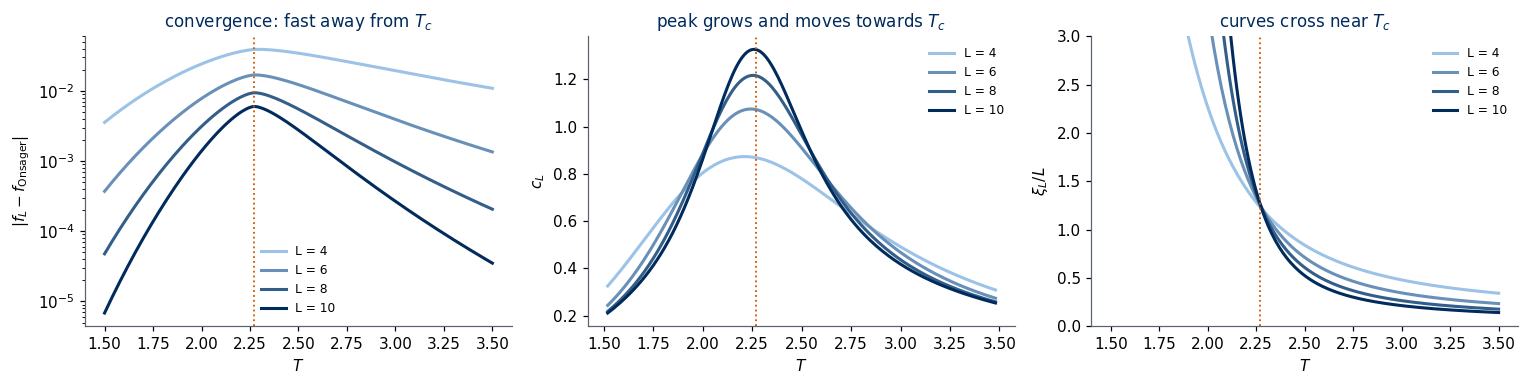

In [13]:
def f_onsager(T):
    # Onsager 1944: -beta f = ln(2 cosh 2K) + (1/2pi) int_0^pi ln[(1 + sqrt(1 - kappa^2 sin^2 phi))/2] dphi
    K = 1.0 / T
    k = 2 * np.sinh(2 * K) / np.cosh(2 * K)**2
    g = lambda p: np.log(0.5 * (1 + np.sqrt(max(0.0, 1 - k**2 * np.sin(p)**2))))
    with warnings.catch_warnings():                 # at T = T_c the integrand has a kink; quad warns but the result is accurate
        warnings.simplefilter("ignore", IntegrationWarning)
        I, _ = quad(g, 0, np.pi, points=[np.pi / 2], limit=200, epsabs=1e-13, epsrel=1e-13)
    return -T * (np.log(2 * np.cosh(2 * K)) + I / (2 * np.pi))

Ls = [4, 6, 8, 10]
Tgrid = np.linspace(1.5, 3.5, 201); dT = Tgrid[1] - Tgrid[0]
strip = {}
t0 = time.perf_counter()
for L in Ls:
    lam = np.array([lambda01(L, 1 / T) for T in Tgrid])
    fL = -Tgrid * np.log(lam[:, 0]) / L
    cL = -Tgrid * np.gradient(np.gradient(fL, dT), dT)
    xiL = 1 / np.log(lam[:, 0] / lam[:, 1])
    strip[L] = dict(f=fL, c=cL, xi=xiL)
print(f"strip transfer matrices: {time.perf_counter() - t0:.1f} s")
f_inf = np.array([f_onsager(T) for T in Tgrid])

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for i, L in enumerate(Ls):
    col = blues(i / (len(Ls) - 1))
    ax[0].semilogy(Tgrid, np.abs(strip[L]["f"] - f_inf), color=col, lw=2, label=f"L = {L}")
    s = slice(2, -2)                                                   # drop the one-sided ends of np.gradient
    ax[1].plot(Tgrid[s], strip[L]["c"][s], color=col, lw=2, label=f"L = {L}")
    k = np.argmax(strip[L]["c"][s])
    print(f"L = {L:2d}:  c_max = {strip[L]['c'][s][k]:.4f} at T = {Tgrid[s][k]:.3f};   "
          f"|f_L - f| at T = 1.5, T_c, 3.5:  {abs(strip[L]['f'][0]-f_inf[0]):.1e}, "
          f"{abs(-TC*np.log(lambda01(L, KC)[0])/L - f_onsager(TC)):.1e}, {abs(strip[L]['f'][-1]-f_inf[-1]):.1e}")
    ax[2].plot(Tgrid, strip[L]["xi"] / L, color=col, lw=2, label=f"L = {L}")
for a in ax:
    a.axvline(TC, color=DSOrange, ls=":", lw=1.2); a.set_xlabel("$T$"); a.legend(frameon=False, fontsize=8)
ax[0].set_ylabel(r"$|f_L - f_{\rm Onsager}|$"); ax[0].set_title("convergence: fast away from $T_c$")
ax[1].set_ylabel("$c_L$"); ax[1].set_title("peak grows and moves towards $T_c$")
ax[2].set_ylabel(r"$\xi_L / L$"); ax[2].set_ylim(0, 3); ax[2].set_title(r"curves cross near $T_c$")
plt.tight_layout(); plt.show()

Away from $T_c$, $f_L$ converges to Onsager's $f$ exponentially fast in $L$: at $T=1.5$ the error falls from $3.5\times10^{-3}$ for $L=4$ to $6.8\times10^{-6}$
for $L=10$. The correlation length there is finite, and a strip much wider than $\xi$ behaves like the infinite plane. At $T_c$ the convergence is only a power law,
proportional to $1/L^2$ (Section 8.1), because the strip is never wider than $\xi=\infty$; the error decreases only from $3.9\times10^{-2}$ to $6.0\times10^{-3}$.
Meanwhile the peak of $c_L$ grows, from $0.8728$ to $1.3262$, and moves towards $T_c$, from $T=2.210$ to $T=2.260$. The growth is slow, and Section 8 will show that the
divergence is logarithmic. This is how a singularity of the infinite system announces itself in finite ones.

The third panel is the most useful. Above $T_c$ the ratio $\xi_L/L$ decreases with $L$, because $\xi$ is finite and $\xi_L$ saturates while $L$ grows. Below $T_c$ it
increases: the two ordered states, all up and all down, become degenerate, $\lambda_1\to\lambda_0$ and $\xi_L\to\infty$. Exactly at $T_c$, where the only length scale is
$L$ itself, the ratio is independent of $L$. The curves for $L$ and $L+2$ therefore cross near $T_c$, and their crossing points locate it — the same logic as the
finite-size analysis of the CNN, but now with an exact algorithm.

### 3.2 Crossings of the scaled correlation length
For each pair of widths $(L, L+2)$ we solve $\xi_L(T)/L = \xi_{L+2}(T)/(L+2)$ for $T$ by root finding (`brentq`) and compare the crossing temperature $T^*(L)$ with the exact $T_c$.

In [14]:
def xi_over_L(L, T, lattice="square"):
    l0, l1 = lambda01(L, 1 / T, lattice)
    return 1 / np.log(l0 / l1) / L

print(" L, L+2   crossing T*(L)      T*(L) - T_c")
for L in (4, 6, 8, 10):
    t0 = time.perf_counter()
    Tx = brentq(lambda T: xi_over_L(L, T) - xi_over_L(L + 2, T), 2.0, 2.6, xtol=1e-12)
    print(f"{L:2d}, {L+2:2d}   {Tx:.8f}      {Tx - TC:+.2e}     ({time.perf_counter()-t0:.1f} s)")
print(f"exact T_c = {TC:.8f}")

 L, L+2   crossing T*(L)      T*(L) - T_c
 4,  6   2.28780299      +1.86e-02     (0.0 s)
 6,  8   2.27494894      +5.76e-03     (0.1 s)


 8, 10   2.27168848      +2.50e-03     (0.5 s)


10, 12   2.27050963      +1.32e-03     (13.8 s)
exact T_c = 2.26918531


The crossings approach $T_c$ quickly, the deviation shrinking from $1.86\times10^{-2}$ for the pair $(4,6)$ to $1.32\times10^{-3}$ for $(10,12)$. With matrices of size at most
$2^{12}\times2^{12}$ we obtain $T_c$ to about three digits, free of Monte Carlo noise. For $L = 50$ the matrix would have $2^{50}\approx10^{15}$ rows, which no computer
can diagonalise. Onsager's achievement was to find $\lambda_0$ **analytically** for every $L$ (Section 6).

### 3.3 One and two dimensions
The strips let us see directly why 2D differs from 1D. The 1D chain has $\xi = -1/\ln\tanh K$, finite at every $T>0$, and its specific heat $K^2/\cosh^2K$ is one smooth bump.
In 2D the strip correlation lengths grow without bound below $T_c$, and above $T_c$ they converge to the exact 2D correlation length along a lattice axis,
$\xi = 1/[2(K^*-K)]$, with $K^*$ the dual coupling defined by $e^{-2K^*}=\tanh K$ (the formula is derived and checked in Sections 5 and 6.1).
This $\xi$ diverges at $T_c$, where $K^*=K$.

A simple balance of energy against entropy explains the difference. Start from an open 1D chain of $N$ spins, all up. Breaking one bond, that is inserting one domain wall,
costs energy $2J$, and the wall can sit at any of $N-1$ positions, which is an entropy $\ln(N-1)$. The free-energy change $\Delta F = 2J - T\ln(N-1)$ is negative once
$N-1>e^{2J/T}$, so at any $T>0$ a long enough chain breaks into domains, of typical length $\sim e^{2K}$, in line with $\xi\approx\frac12e^{2K}$ from Section 2.1.

In 2D a domain of flipped spins is bounded by a closed wall, and a wall of length $\ell$ (number of broken bonds) costs $2J\ell$ — an energy proportional to its length,
not a constant. The number of closed walls of length $\ell$ through a given bond is at most the number of lattice paths of $\ell$ steps that never immediately step back,
$4\cdot3^{\ell-1}$. The entropy is therefore at most about $\ell\ln3$, and $\Delta F\gtrsim\ell\,(2J-T\ln3)$, which is positive for $T<2J/\ln3\approx1.82$.
Large flipped domains are suppressed and the order survives at low $T$. This is the idea of Peierls' argument [Peierls 1936; rigorous form: Griffiths 1964];
it gives a lower bound on the ordering temperature, consistent with $T_c\approx2.269>1.82$.

The next cell evaluates these numbers — the temperature above which one wall lowers $F$ for chains of $10$, $10^3$ and $10^6$ spins drops towards zero as the chain
grows, while the 2D bound stays at $1.8205$ — and plots $\xi$ and $c$ for 1D and 2D side by side.

1D chain, N =      10: one domain wall lowers F (Delta F = 2 - T ln(N-1) < 0) for T > 0.9102
1D chain, N =    1000: one domain wall lowers F (Delta F = 2 - T ln(N-1) < 0) for T > 0.2896
1D chain, N = 1000000: one domain wall lowers F (Delta F = 2 - T ln(N-1) < 0) for T > 0.1448
2D: the bound Delta F >~ l (2 - T ln 3) is positive for T < 2/ln 3 = 1.8205;   exact T_c = 2.2692


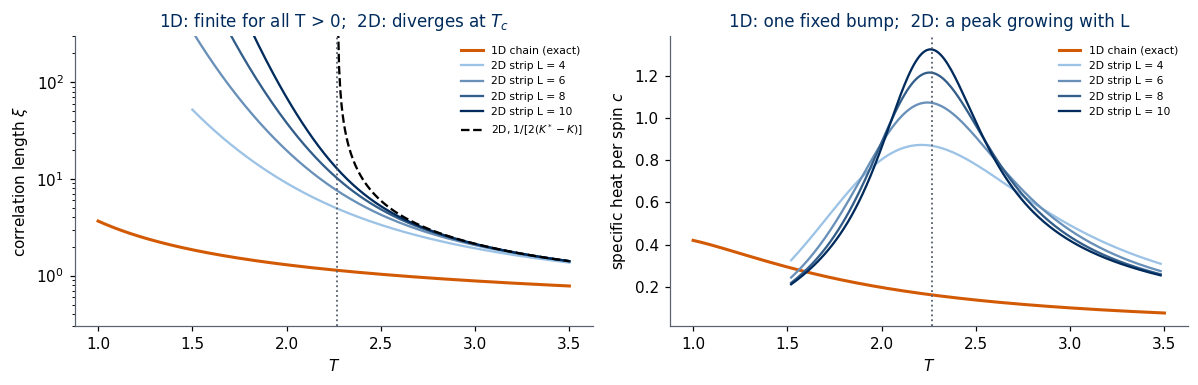

In [15]:
# 1D chain versus 2D strips: correlation length and specific heat
for Nch in (10, 10**3, 10**6):
    print(f"1D chain, N = {Nch:>7d}: one domain wall lowers F (Delta F = 2 - T ln(N-1) < 0) for T > {2/np.log(Nch-1):.4f}")
print(f"2D: the bound Delta F >~ l (2 - T ln 3) is positive for T < 2/ln 3 = {2/np.log(3):.4f};   exact T_c = {TC:.4f}")

Tq = np.linspace(1.0, 3.5, 400)
xi_1d = -1 / np.log(np.tanh(1 / Tq))
Kq = 1 / Tq; Kq_dual = -0.5 * np.log(np.tanh(Kq))
xi_2d = np.where(Tq > TC, 1 / (2 * (Kq_dual - Kq)), np.nan)        # exact, T > T_c (Section 6.1)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(Tq, xi_1d, color=DSOrange, lw=2, label="1D chain (exact)")
for i, L in enumerate(Ls):
    ax[0].plot(Tgrid, strip[L]["xi"], color=blues(i / (len(Ls) - 1)), lw=1.5, label=f"2D strip L = {L}")
ax[0].plot(Tq, xi_2d, color="k", ls="--", lw=1.5, label=r"2D, $1/[2(K^*-K)]$")
ax[0].set_yscale("log"); ax[0].set_ylim(0.3, 300); ax[0].set_ylabel(r"correlation length $\xi$")
ax[0].set_title("1D: finite for all T > 0;  2D: diverges at $T_c$")
ax[1].plot(Tq, 1 / Tq**2 / np.cosh(1 / Tq)**2, color=DSOrange, lw=2, label="1D chain (exact)")
for i, L in enumerate(Ls):
    ax[1].plot(Tgrid[2:-2], strip[L]["c"][2:-2], color=blues(i / (len(Ls) - 1)), lw=1.5, label=f"2D strip L = {L}")
ax[1].set_ylabel("specific heat per spin $c$"); ax[1].set_title("1D: one fixed bump;  2D: a peak growing with L")
for a in ax:
    a.axvline(TC, color=UJGray, ls=":", lw=1.2); a.set_xlabel("$T$"); a.legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.show()

<hr/>
## 4. High- and low-temperature expansions of $Z$

Before Onsager, the 2D model was studied through expansions of $Z$ that are accurate far from $T_c$, in powers of a small parameter at high $T$ and at low $T$.
For us their value is structural: the two series turn out to count *the same* geometric objects, and this coincidence (Section 5) pins down $T_c$ exactly.

### 4.1 High-temperature expansion and closed graphs
At high $T$ the coupling $K$ is small. Since $ss'=\pm1$ and $e^{\pm K}=\cosh K\pm\sinh K$,
$$
e^{Kss'} = \cosh K + ss'\sinh K = \cosh K\,(1 + t\,ss'),\qquad t = \tanh K .
$$
Inserting this for every one of the $2N$ bonds gives
$$
Z = (\cosh K)^{2N}\sum_{\mathbf s}\prod_{\langle i,j\rangle}\big(1 + t\,s_is_j\big).
$$
To expand the product we pick from each bond factor either $1$ or $t\,s_is_j$. A choice is a subset $G$ of bonds, those where $t\,s_is_j$ was picked, and it contributes
$t^{|G|}\prod_{\langle i,j\rangle\in G}s_is_j = t^{|G|}\prod_i s_i^{d_i(G)}$, where $d_i(G)$ is the number of bonds of $G$ touching site $i$.
Summing over the spins now removes most subsets: $\sum_{s=\pm1}s^d$ equals $2$ for even $d$ and $0$ for odd $d$, so a subset survives only if every site has an even
number of its bonds, that is, if $G$ is a **closed graph** (a union of closed loops). Hence
$$
Z = 2^N(\cosh K)^{2N}\sum_{\text{closed } G}t^{|G|} = 2^N(\cosh K)^{2N}\big(1 + N t^4 + 2N t^6 + \dots\big).
$$
The smallest closed graph is the boundary of one plaquette (4 bonds; there are $N$ plaquettes), and the next is the boundary of a $1\times2$ rectangle
(6 bonds; $N$ horizontal and $N$ vertical ones).

### 4.2 Low-temperature expansion and domain walls
At low $T$ almost all spins are parallel. Starting from all spins up, $E_0 = -2N$, a configuration with $b$ broken bonds has $E=-2N+2b$ (Section 1.1) and hence
the weight $e^{2NK}x^{b}$ with $x = e^{-2K}$, small at low $T$. Draw a short segment across each broken bond. These segments live on the **dual lattice**, whose sites are
the centres of the plaquettes. Going around a plaquette the spin returns to its starting value, so it changes sign an even number of times, and every dual site touches
an even number of segments. The broken bonds therefore form **closed graphs on the dual lattice** — the domain walls. Each wall pattern comes from exactly two spin
configurations, $\mathbf s$ and $-\mathbf s$, so
$$
Z = 2e^{2NK}\sum_{\text{closed walls } W}x^{|W|} = 2e^{2NK}\big(1 + N x^4 + 2N x^6 + \dots\big):
$$
one flipped spin breaks 4 bonds ($N$ ways), and a flipped neighbouring pair breaks 6 bonds ($2N$ ways).

The sketch below places the two expansions side by side. On the left are the two smallest closed graphs, the boundary of one plaquette (4 bonds, weight $t^4$) and of a $1\times2$ rectangle (6 bonds, weight $t^6$); the spins have been summed out, so only the bonds matter. On the right are the two smallest excitations of the all-up state, one flipped spin and two flipped neighbours. Each broken bond is crossed by a segment of the dual lattice (dotted), and these segments form a closed domain wall of length 4 (weight $x^4$) or 6 (weight $x^6$). The shapes are the same on both sides.

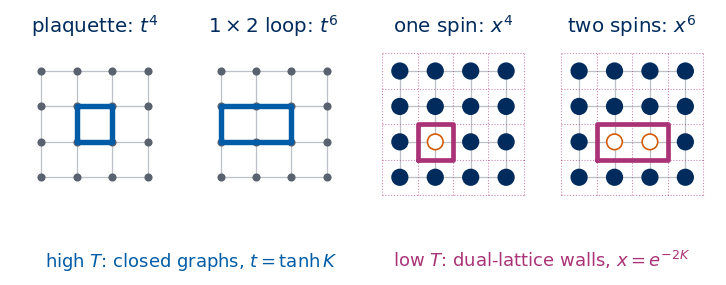

In [ ]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("figures", exist_ok=True)
    for d in ("figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def draw_spin(ax, x, y, s, r=0.26, sign=False, alpha=1.0, fs=10, lw=1.3):
    # one Ising spin at (x, y): navy disc for s = +1, white disc with orange rim for s = -1 (optionally with "+" / "-")
    face, edge, txt = (NAVY, NAVY, "white") if s > 0 else ("white", ORANGE, ORANGE)
    ax.add_patch(mpatches.Circle((x, y), r, fc=face, ec=edge, lw=lw, alpha=alpha, zorder=4))
    if sign:
        ax.text(x, y, "+" if s > 0 else "−", color=txt, ha="center", va="center", alpha=alpha,
                fontsize=fs, fontweight="bold", zorder=5)

def draw_bond(ax, p, q, broken=False, lw=1.5, alpha=1.0, color=None, cross=True):
    # bond between points p and q: solid blue if satisfied, dashed purple with a cross if broken
    c = color or (PURPLE if broken else BLUE)
    ax.plot([p[0], q[0]], [p[1], q[1]], color=c, lw=lw, ls=(0, (2.5, 1.5)) if broken else "-",
            alpha=alpha, solid_capstyle="round", zorder=2)
    if broken and cross:
        ax.plot((p[0] + q[0]) / 2, (p[1] + q[1]) / 2, marker="x", ms=3.5 * lw, mew=lw * 0.9, color=c, alpha=alpha, zorder=3)

def sketch_closed_graphs_and_walls():
    n = 4                                                           # a 4 x 4 window of the lattice in each panel
    fig, axes = plt.subplots(1, 4, figsize=(5.5, 2.25))
    fig.subplots_adjust(left=0.01, right=0.99, bottom=0.17, top=0.86, wspace=0.1)

    def lattice(ax, dual=False):
        # sites as grey dots, bonds as thin grey lines; optionally the dual lattice (plaquette centres) dotted
        for k in range(n):
            ax.plot([0, n - 1], [k, k], color=GRAY, lw=0.7, alpha=0.4); ax.plot([k, k], [0, n - 1], color=GRAY, lw=0.7, alpha=0.4)
        if dual:
            for k in range(n + 1):
                ax.plot([-0.5, n - 0.5], [k - 0.5, k - 0.5], color=PURPLE, lw=0.6, ls=":", alpha=0.6)
                ax.plot([k - 0.5, k - 0.5], [-0.5, n - 0.5], color=PURPLE, lw=0.6, ls=":", alpha=0.6)
        ax.set_xlim(-0.8, n - 0.2); ax.set_ylim(-0.8, n - 0.2); ax.set_aspect("equal"); ax.axis("off")

    def path(ax, pts, color, lw=3):
        pts = np.array(pts + [pts[0]], float)
        ax.plot(pts[:, 0], pts[:, 1], color=color, lw=lw, solid_capstyle="round", solid_joinstyle="round", zorder=3)

    # high temperature: closed graphs of bonds on the lattice itself, weight t^{|G|}
    for ax, loop, title in [(axes[0], [(1, 1), (2, 1), (2, 2), (1, 2)], "plaquette: $t^4$"),
                            (axes[1], [(0, 1), (2, 1), (2, 2), (0, 2)], r"$1\times2$ loop: $t^6$")]:
        lattice(ax)
        for (x, y) in [(i, j) for i in range(n) for j in range(n)]:
            ax.plot(x, y, "o", color=GRAY, ms=3.5, zorder=2)
        path(ax, loop, BLUE)
        ax.set_title(title, fontsize=11, color=NAVY)

    # low temperature: flipped spins in the all-up state; broken bonds are crossed by dual-lattice segments
    for ax, flipped, title in [(axes[2], [(1, 1)], "one spin: $x^4$"),
                               (axes[3], [(1, 1), (2, 1)], "two spins: $x^6$")]:
        lattice(ax, dual=True)
        S = {(i, j): -1 if (i, j) in flipped else 1 for i in range(n) for j in range(n)}
        for (x, y), s in S.items():
            draw_spin(ax, x, y, s, r=0.22, lw=0.9)
        xs = [p[0] for p in flipped]
        wall = [(min(xs) - 0.5, 0.5), (max(xs) + 0.5, 0.5), (max(xs) + 0.5, 1.5), (min(xs) - 0.5, 1.5)]
        path(ax, wall, PURPLE, lw=2.6)
        ax.set_title(title, fontsize=11, color=NAVY)

    fig.text(0.26, 0.03, r"high $T$: closed graphs, $t=\tanh K$", ha="center", fontsize=10, color=BLUE)
    fig.text(0.75, 0.03, r"low $T$: dual-lattice walls, $x=e^{-2K}$", ha="center", fontsize=10, color=PURPLE)
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_closed_graphs_and_walls()
save_sketch(fig, "sketch_ising_loops_walls.png")
plt.show()


The dual of the square lattice is again a square lattice. For $N\to\infty$ the closed graphs of 4.1 and the domain walls of 4.2 are therefore the same set, and the two
series have the same coefficients, with $t=\tanh K$ at high $T$ playing the role of $x=e^{-2K}$ at low $T$.

We can count both kinds of objects on the $4\times4$ torus using the histogram of Section 1. The low-temperature coefficients are $n_b/2$, so we expect $N = 16$ at $b=4$ and
$2N = 32$ at $b = 6$. The high-temperature coefficients, the numbers of closed graphs with $k$ bonds, also follow exactly from the same histogram: a satisfied bond contributes
$\cosh K\,(1+t)$ and a broken one $\cosh K\,(1-t)$, so $\sum_G t^{|G|} = 2^{-N}\sum_b n_b(1+t)^{2N-b}(1-t)^b$, a polynomial we expand with integer arithmetic.
The first cell below confirms the identity $e^{Kss'} = \cosh K(1+ss'\tanh K)$ symbolically, and the next two do the counting.

In [16]:
# SymPy: e^{K s s'} = cosh K (1 + s s' tanh K) for both values of s s'
K = sp.symbols("K", positive=True)
for ssp in (1, -1):
    print(f"s s' = {ssp:+d}:  e^(K s s') - cosh K (1 + s s' tanh K) =", sp.simplify((sp.exp(K * ssp) - sp.cosh(K) * (1 + ssp * sp.tanh(K))).rewrite(sp.exp)))

s s' = +1:  e^(K s s') - cosh K (1 + s s' tanh K) = 0
s s' = -1:  e^(K s s') - cosh K (1 + s s' tanh K) = 0


In [17]:
N = 16
print(f"4x4 torus:  n_4/2 = {dos[4][4]//2} (expected N = {N}),   n_6/2 = {dos[4][6]//2} (expected 2N = {2*N})")
print(f"            n_8/2 = {dos[4][8]//2}  (here also walls that wind around the small torus contribute)")

4x4 torus:  n_4/2 = 16 (expected N = 16),   n_6/2 = 32 (expected 2N = 32)
            n_8/2 = 212  (here also walls that wind around the small torus contribute)


In [18]:
# high-temperature coefficients on the 4x4 torus from the exact histogram n_b (integer arithmetic)
from math import comb
N = 16
closed = [0] * (2 * N + 1)
for b, n in enumerate(dos[4]):
    if n == 0:
        continue
    for i in range(2 * N - b + 1):                 # (1+t)^(2N-b) (1-t)^b, coefficient of t^(i+j)
        for j in range(b + 1):
            closed[i + j] += int(n) * comb(2 * N - b, i) * comb(b, j) * (-1)**j
assert all(v % 2**N == 0 for v in closed)
closed = [v // 2**N for v in closed]
print("k (bonds):                      ", [k for k in range(0, 11, 2)])
print("closed graphs with k bonds:     ", closed[0:11:2])
print("domain walls with k bonds n_k/2:", [int(dos[4][k]) // 2 for k in range(0, 11, 2)])
print(f"t^4: {closed[4]} = 16 plaquettes + 8 straight loops winding around the torus (4 horizontal, 4 vertical)")
print(f"t^6: {closed[6]} = 32 rectangles + {closed[6] - 32} winding loops with one step aside (2 directions x 4 row pairs x 12)")

k (bonds):                       [0, 2, 4, 6, 8, 10]
closed graphs with k bonds:      [1, 0, 24, 128, 876, 3584]
domain walls with k bonds n_k/2: [1, 0, 16, 32, 212, 864]
t^4: 24 = 16 plaquettes + 8 straight loops winding around the torus (4 horizontal, 4 vertical)
t^6: 128 = 32 rectangles + 96 winding loops with one step aside (2 directions x 4 row pairs x 12)


On the small torus the two lists differ, and the reason is instructive. A straight loop of 4 bonds that winds around the $4\times4$ torus is a closed graph,
since every site touches 0 or 2 of its bonds, but it cannot be a domain wall: walking once around the torus perpendicular to it, the spin would change sign once and
could not return to its starting value. Such winding graphs have length at least $L$, and their contribution per spin vanishes for $N\to\infty$, where the two series coincide.

The sketch below illustrates this argument. On the left, a straight row of four bonds closes on itself through the periodic boundary: each site touches 0 or 2 of its bonds, so it is a closed graph of the high-temperature series. On the right, two straight domain walls wind around the torus. Crossing a wall flips the spin, and a spin carried once around the torus must return to its own value, so it crosses an even number of walls: a single winding wall is impossible.

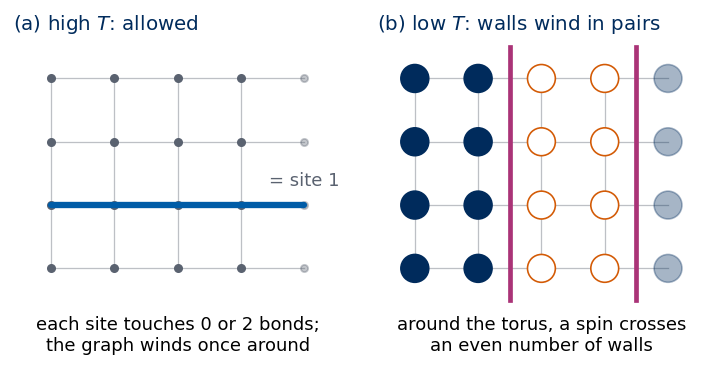

In [ ]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("figures", exist_ok=True)
    for d in ("figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def draw_spin(ax, x, y, s, r=0.26, sign=False, alpha=1.0, fs=10, lw=1.3):
    # one Ising spin at (x, y): navy disc for s = +1, white disc with orange rim for s = -1 (optionally with "+" / "-")
    face, edge, txt = (NAVY, NAVY, "white") if s > 0 else ("white", ORANGE, ORANGE)
    ax.add_patch(mpatches.Circle((x, y), r, fc=face, ec=edge, lw=lw, alpha=alpha, zorder=4))
    if sign:
        ax.text(x, y, "+" if s > 0 else "−", color=txt, ha="center", va="center", alpha=alpha,
                fontsize=fs, fontweight="bold", zorder=5)

def draw_bond(ax, p, q, broken=False, lw=1.5, alpha=1.0, color=None, cross=True):
    # bond between points p and q: solid blue if satisfied, dashed purple with a cross if broken
    c = color or (PURPLE if broken else BLUE)
    ax.plot([p[0], q[0]], [p[1], q[1]], color=c, lw=lw, ls=(0, (2.5, 1.5)) if broken else "-",
            alpha=alpha, solid_capstyle="round", zorder=2)
    if broken and cross:
        ax.plot((p[0] + q[0]) / 2, (p[1] + q[1]) / 2, marker="x", ms=3.5 * lw, mew=lw * 0.9, color=c, alpha=alpha, zorder=3)

def sketch_winding_loop():
    L = 4
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(5.5, 2.9))
    fig.subplots_adjust(left=0.01, right=0.99, bottom=0.01, top=0.9, wspace=0.08)
    for ax in (ax1, ax2):
        for k in range(L):
            ax.plot([0, L], [k, k], color=GRAY, lw=0.7, alpha=0.4); ax.plot([k, k], [0, L - 1], color=GRAY, lw=0.7, alpha=0.4)
        ax.set_xlim(-0.6, L + 0.6); ax.set_ylim(-1.7, L - 0.4); ax.set_aspect("equal"); ax.axis("off")

    # (a) a closed graph that winds around the torus: the 4 horizontal bonds of row 1, the last one wrapping to the copy of column 0
    for x in range(L + 1):
        for y in range(L):
            ax1.plot(x, y, "o", color=GRAY, ms=4, alpha=0.35 if x == L else 1, zorder=2)
    ax1.plot([0, L], [1, 1], color=BLUE, lw=3.5, solid_capstyle="round", zorder=3)
    ax1.text(L, 1.25, "= site 1", fontsize=10, color=GRAY, va="bottom", ha="center")
    ax1.text(L / 2, -0.75, "each site touches 0 or 2 bonds;\nthe graph winds once around", ha="center", va="top", fontsize=10)
    ax1.set_title("(a) high $T$: allowed", fontsize=11, color=NAVY, loc="left")

    # (b) a single winding domain wall is impossible: walking around the torus across it flips the spin once,
    #     so the spins left and right of the wrap-around would disagree; walls that wind come in pairs
    S = np.ones((L, L + 1), int); S[:, 2:4] = -1                   # columns 2, 3 flipped; column 4 is the copy of column 0
    for x in range(L + 1):
        for y in range(L):
            draw_spin(ax2, x, y, S[y, x], r=0.22, lw=0.9, alpha=0.35 if x == L else 1)
    for xw in (1.5, 3.5):
        ax2.plot([xw, xw], [-0.5, L - 0.5], color=PURPLE, lw=2.6, zorder=3)
    ax2.text(L / 2, -0.75, "around the torus, a spin crosses\nan even number of walls",
             ha="center", va="top", fontsize=10)
    ax2.set_title("(b) low $T$: walls wind in pairs", fontsize=11, color=NAVY, loc="left")
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_winding_loop()
save_sketch(fig, "sketch_ising_winding_loop.png")
plt.show()


A second test compares the leading terms with the exact free energy of the infinite lattice. Per spin,
$\frac1N\ln(1 + Nt^4 + 2Nt^6+\dots) = t^4 + 2t^6 + O(t^8)$: pairs of separate plaquettes give a term $\approx\frac{N^2}{2}t^8$ inside the logarithm,
which is cancelled by $-\frac12(Nt^4)^2$ from $\ln(1+y)=y-\frac{y^2}{2}+\dots$, leaving only terms proportional to $N$. The ratios
$$
\begin{aligned}
R_{\rm high}(K) &= \frac{\ln Z/N - \ln2 - 2\ln\cosh K}{t^4 + 2t^6}\xrightarrow{K\to0}1,\\
R_{\rm low}(K) &= \frac{\ln Z/N - 2K}{x^4 + 2x^6}\xrightarrow{K\to\infty}1 ,
\end{aligned}
$$
with $\ln Z/N$ taken from Onsager's formula (Section 6), should therefore approach one in the respective limits.

In [19]:
def phi(K):                       # phi = ln Z / N = -beta f  (Onsager, N -> infinity)
    return -f_onsager(1 / K) / (1 / K)

print("   K      R_high        K      R_low")
for Kh, Kl in zip([0.05, 0.1, 0.15, 0.2, 0.25], [2.0, 1.5, 1.2, 1.0, 0.8]):
    t = np.tanh(Kh); x = np.exp(-2 * Kl)
    Rh = (phi(Kh) - np.log(2) - 2 * np.log(np.cosh(Kh))) / (t**4 + 2 * t**6)
    Rl = (phi(Kl) - 2 * Kl) / (x**4 + 2 * x**6)
    print(f"  {Kh:4.2f}   {Rh:.6f}     {Kl:4.2f}   {Rl:.6f}")

   K      R_high        K      R_low
  0.05   1.000028     2.00   1.000001
  0.10   1.000447     1.50   1.000028
  0.15   1.002252     1.20   1.000307
  0.20   1.007086     1.00   1.001532
  0.25   1.017319     0.80   1.007776


Both ratios indeed tend to $1$: $R_{\rm high}=1.000028$ at $K=0.05$ and $R_{\rm low}=1.000001$ at $K=2$. The deviation is the next order of the series,
proportional to $t^4$ and $x^4$ relative to the leading term. **Both series have the same coefficients** $1, N, 2N,\dots$ because the closed graphs on the square
lattice and on its dual are the same set. This property is **self-duality**, and the next section turns it into an exact statement about $T_c$.

<hr/>
## 5. Kramers–Wannier duality and the self-dual point

The coincidence of the two series relates the free energy at a high temperature to the free energy at a low temperature. Kramers and Wannier [1941] used it to find
$T_c$ exactly, three years before Onsager's full solution. It is the most economical route to $T_c$, and it explains why the modulus $\kappa$ of Onsager's formula
takes the same value at two different temperatures.

Let $g(y) = \lim_{N\to\infty}\frac1N\ln\sum_G y^{|G|}$, the sum running over closed graphs. Both expansions of Section 4 contain this same function, evaluated at
two different arguments:
$$
\varphi(K) \equiv \lim_{N\to\infty}\frac{\ln Z(K)}{N} = \ln 2 + 2\ln\cosh K + g(\tanh K) = 2K + g\big(e^{-2K}\big).
$$
To compare them we need a coupling at which the low-temperature argument equals the high-temperature one. Define the dual coupling $K^*$ by $e^{-2K^*} = \tanh K$.
The low-temperature form at $K^*$ reads $\varphi(K^*) = 2K^* + g(e^{-2K^*}) = 2K^* + g(\tanh K)$, and subtracting the high-temperature form at $K$ eliminates the unknown $g$:
$$
\boxed{\ \varphi(K) - \ln2 - 2\ln\cosh K = \varphi(K^*) - 2K^*\ }.
$$
The free energy at $K$ is thus fixed by the free energy at $K^*$ plus elementary analytic functions.

The map $K\mapsto K^*$ has simple properties. With $t=\tanh K = e^{-2K^*}$,
$$
\begin{aligned}
\sinh 2K^* &= \frac{e^{2K^*}-e^{-2K^*}}{2} = \frac{1/t - t}{2} = \frac{1-t^2}{2t},\\
\sinh 2K &= \frac{2\tanh K}{1-\tanh^2K} = \frac{2t}{1-t^2}\\
\Rightarrow\quad \sinh2K\,\sinh2K^* &= 1 .
\end{aligned}
$$
This relation is symmetric in $K$ and $K^*$, so the map is an involution, $K^{**}=K$, and equivalently $\tanh K^* = e^{-2K}$. It is also decreasing: a small $K$ (hot)
maps to a large $K^*$ (cold), and vice versa.

Now comes the argument for $T_c$. The functions $\ln 2$, $2\ln\cosh K$ and $2K^*$ are analytic for $K>0$, so if $\varphi$ is non-analytic at some $K_c$, the boxed
identity makes it non-analytic at $K_c^*$ as well. If the model has a **single** transition, the two points must coincide, $K_c = K_c^*$:
$$
\sinh^2 2K_c = 1\ \Rightarrow\ \sinh 2K_c = 1\ \Rightarrow\ e^{2K_c}-e^{-2K_c} = 2 .
$$
With $y=e^{2K_c}$ this is $y^2-2y-1=0$, whose positive root is $y = 1+\sqrt2$. Hence
$$
K_c = \tfrac12\ln(1+\sqrt2)\approx0.4407,\qquad T_c = \frac{2}{\ln(1+\sqrt2)}\approx2.2692 .
$$
The assumption of a single transition is the only gap in the argument, and Onsager's solution closes it.

Duality also explains a property of Onsager's formula. With $s=\sinh2K$ we have $\cosh^22K = 1+s^2$ and $\kappa = 2s/(1+s^2)$. Replacing $s$ by $s^*=1/s$ gives
$\kappa^* = \frac{2/s}{1+1/s^2} = \frac{2s}{s^2+1} = \kappa$, so the temperatures $T$ and $T^*$ give the same integrand in Onsager's formula.

We confirm all of this in three cells: first symbolically, then numerically. The checks are that (i) $\sinh2K\sinh2K^*=1$, (ii) $\kappa(K) = \kappa(K^*)$, (iii) the boxed
identity holds for Onsager's $f$, (iv) the fixed point of $K\mapsto K^*$, found by root finding, is $K_c$, and (v) at that point $\tanh K_c = e^{-2K_c} = \sqrt2-1$.

SymPy first verifies the properties of the dual map, the self-duality of $\kappa$ and the solution of $\sinh 2K = 1$; the numerical table and the root finding follow.

In [20]:
K = sp.symbols("K", positive=True)
K_star = -sp.log(sp.tanh(K)) / 2                                            # e^{-2K*} = tanh K
kappa_sym = lambda k: 2 * sp.sinh(2 * k) / sp.cosh(2 * k)**2
print("sinh 2K sinh 2K*        =", sp.simplify((sp.sinh(2 * K) * sp.sinh(2 * K_star)).rewrite(sp.exp)))
print("tanh K* - e^{-2K}       =", sp.simplify((sp.tanh(K_star) - sp.exp(-2 * K)).rewrite(sp.exp)))
print("kappa(K) - kappa(K*)    =", sp.simplify((kappa_sym(K) - kappa_sym(K_star)).rewrite(sp.exp)))
print("dK*/dK + 1/sinh 2K      =", sp.simplify((sp.diff(K_star, K) + 1 / sp.sinh(2 * K)).rewrite(sp.exp)))
Kc_sym = [sp.simplify(s.rewrite(sp.log)) for s in sp.solve(sp.Eq(sp.sinh(2 * K), 1), K)]
print("solution of sinh 2K = 1 :", Kc_sym)
Kc_sym = sp.log(1 + sp.sqrt(2)) / 2
print("check: sinh 2K_c =", sp.simplify(sp.sinh(2 * Kc_sym).rewrite(sp.exp)),
      ";  tanh K_c =", sp.radsimp(sp.simplify(sp.tanh(Kc_sym).rewrite(sp.exp))),
      ";  e^{-2K_c} =", sp.radsimp(sp.exp(-2 * Kc_sym)),
      ";  T_c = 1/K_c =", sp.N(1 / Kc_sym, 12))

sinh 2K sinh 2K*        = 1
tanh K* - e^{-2K}       = 0


kappa(K) - kappa(K*)    = 0


dK*/dK + 1/sinh 2K      = 0
solution of sinh 2K = 1 : [log(1 + sqrt(2))/2]


check: sinh 2K_c = 1 ;  tanh K_c = -1 + sqrt(2) ;  e^{-2K_c} = -1 + sqrt(2) ;  T_c = 1/K_c = 2.26918531421


In [21]:
def K_dual(K):
    return -0.5 * np.log(np.tanh(K))

def kappa(K):
    return 2 * np.sinh(2 * K) / np.cosh(2 * K)**2

print("    T       T*       sinh2K sinh2K*     kappa(K)    kappa(K*)    duality identity residual")
for T in (1.0, 1.6, 2.0, 2.2, 2.5, 3.0, 4.0):
    K = 1 / T; Ks = K_dual(K)
    lhs = phi(K) - np.log(2) - 2 * np.log(np.cosh(K)); rhs = phi(Ks) - 2 * Ks
    print(f"  {T:4.2f}   {1/Ks:7.4f}     {np.sinh(2*K)*np.sinh(2*Ks):.12f}   {kappa(K):.10f}  {kappa(Ks):.10f}   {lhs-rhs:+.1e}")

K_fixed = brentq(lambda K: K - K_dual(K), 0.1, 1.0, xtol=1e-15)
print(f"\nself-dual point from root finding: K = {K_fixed:.12f},  T = {1/K_fixed:.10f}")
print(f"ln(1+sqrt2)/2 = {np.log(1+np.sqrt(2))/2:.12f},   sinh(2K) at the fixed point = {np.sinh(2*K_fixed):.12f}")

    T       T*       sinh2K sinh2K*     kappa(K)    kappa(K*)    duality identity residual
  1.00    7.3437     1.000000000000   0.5124813589  0.5124813589   +5.6e-17
  1.60    3.3927     1.000000000000   0.8984038491  0.8984038491   -2.2e-16
  2.00    2.5909     1.000000000000   0.9871086951  0.9871086951   +1.4e-16
  2.20    2.3414     1.000000000000   0.9992468260  0.9992468260   +1.4e-16
  2.50    2.0667     1.000000000000   0.9930004777  0.9930004777   +5.0e-16
  3.00    1.7626     1.000000000000   0.9471713153  0.9471713153   -1.1e-16
  4.00    1.4216     1.000000000000   0.8196284433  0.8196284433   -8.3e-17

self-dual point from root finding: K = 0.440686793510,  T = 2.2691853142
ln(1+sqrt2)/2 = 0.440686793510,   sinh(2K) at the fixed point = 1.000000000000


In [22]:
print(f"(v) tanh K_c = {np.tanh(KC):.12f},  e^(-2 K_c) = {np.exp(-2*KC):.12f},  sqrt2 - 1 = {np.sqrt(2)-1:.12f}")
print(f"    involution: K** - K at K = 0.3: {K_dual(K_dual(0.3)) - 0.3:+.1e}")

(v) tanh K_c = 0.414213562373,  e^(-2 K_c) = 0.414213562373,  sqrt2 - 1 = 0.414213562373
    involution: K** - K at K = 0.3: +5.6e-17


The column $T^*$ shows the map at work: ordered temperatures $T<T_c$ are mapped onto disordered ones $T^*>T_c$ and vice versa, and $T_c$ is the only fixed point,
found by root finding at $K = 0.440686793510$, which is $\frac12\ln(1+\sqrt2)$ to all printed digits. The residual of the duality identity stays at the level of rounding errors
at every temperature. The pair $T = 1.6$ and $T^* = 3.3927$ gives the same $\kappa = 0.8984038491$, hence the same integrand in Onsager's formula; we shall plot this integrand in Section 6.

<hr/>
## 6. Onsager's formula and its consequences

Section 3 showed that the free energy of the plane is $\lim_{L\to\infty}-\frac{T}{L}\ln\lambda_0(L)$, but numerically we could reach only $L\approx12$.
Onsager found $\lambda_0(L)$ in closed form for every $L$ and took the limit. The result is
$$
\begin{aligned}
-\beta f &= \ln(2\cosh2K) + \frac{1}{2\pi}\int_0^\pi d\phi\,\ln\Big[\tfrac12\Big(1+\sqrt{1-\kappa^2\sin^2\phi}\Big)\Big],\\
\kappa &= \frac{2\sinh2K}{\cosh^22K} .
\end{aligned}
$$
Subsection 6.1 outlines the modern derivation, in which the transfer matrix becomes a problem of *free fermions* [Kaufman 1949; Schultz, Mattis & Lieb 1964].
We state the key equation of each stage and verify each of them numerically; the full algebra is in Schultz, Mattis & Lieb (1964) and, in open access, in Gispen (2018).
Subsections 6.2 and 6.3 then interpret the result and derive the energy, the specific heat and the magnetisation.

### 6.1 From spins to free fermions

The derivation begins by rewriting the transfer matrix with Pauli matrices. Let $\sigma^x=\begin{pmatrix}0&1\\1&0\end{pmatrix}$, $\sigma^z=\begin{pmatrix}1&0\\0&-1\end{pmatrix}$,
and let $\sigma^a_i$ act on the spin of row $i$ (and as the identity on the other rows). For a single row, the horizontal-bond weight $e^{Kss'}$ is the $2\times2$ matrix
$$
\begin{pmatrix}e^K&e^{-K}\\e^{-K}&e^K\end{pmatrix} = e^K\mathbb 1 + e^{-K}\sigma^x = \sqrt{2\sinh2K}\;e^{K^*\sigma^x},
$$
with $K^*$ the dual coupling of Section 5 (the identity is proved in Exercise 3). The vertical bonds inside a column are diagonal in the spin basis. Therefore
$$
\begin{aligned}
\mathsf V &= (2\sinh 2K)^{L/2}\;\mathsf V_2^{1/2}\,\mathsf V_1\,\mathsf V_2^{1/2},\\
\mathsf V_1 &= \exp\Big(K^*\sum_{i=1}^L\sigma^x_i\Big),\qquad \mathsf V_2 = \exp\Big(K\sum_{i=1}^L\sigma^z_i\sigma^z_{i+1}\Big).
\end{aligned}
$$
$\mathsf V_2$ weighs the bonds within a column, and $\mathsf V_1$ flips spins from one column to the next. The exponents are those of a *quantum* spin chain — an Ising
coupling $\sigma^z_i\sigma^z_{i+1}$ plus a transverse field $\sigma^x_i$ — so the classical 2D model is equivalent to a quantum chain in 1D.
The difficulty is that $\sigma^x_i$ and $\sigma^z_i$ do not commute, so $\mathsf V_1$ and $\mathsf V_2$ cannot be combined or diagonalised together.

The way out is the Jordan–Wigner transformation, which turns spins into fermions. First rename the axes, $\sigma^x\to-\sigma^z$, $\sigma^z\to\sigma^x$, a unitary change
of basis that leaves the eigenvalues unchanged, so that $\mathsf V_1=\exp(-K^*\sum_j\sigma^z_j)$ and $\mathsf V_2=\exp(K\sum_j\sigma^x_j\sigma^x_{j+1})$.
With $\sigma^+=\begin{pmatrix}0&1\\0&0\end{pmatrix}$ and $\sigma^-=\begin{pmatrix}0&0\\1&0\end{pmatrix}$ define
$$
\psi_j = \Big(\prod_{k<j}(-\sigma^z_k)\Big)\,\sigma^-_j .
$$
The "string" $\prod_{k<j}(-\sigma^z_k)$ makes operators on different sites anticommute: $\{\psi_i,\psi_j^\dagger\}=\delta_{ij}$ and $\{\psi_i,\psi_j\}=0$, where $\{A,B\}=AB+BA$.
These are the relations of **fermion** annihilation and creation operators, and $n_j=\psi_j^\dagger\psi_j$, with eigenvalues 0 and 1, counts the fermion at site $j$.
The spin operators become
$$
\begin{aligned}
\sigma^z_j &= 2n_j-1,\\
\sigma^x_j\sigma^x_{j+1} &= (\psi_j^\dagger-\psi_j)(\psi_{j+1}^\dagger+\psi_{j+1})\quad(j<L),\\
\sigma^x_L\sigma^x_1 &= -(-1)^F(\psi_L^\dagger-\psi_L)(\psi_1^\dagger+\psi_1),
\end{aligned}
$$
with $F=\sum_jn_j$ the number of fermions and $(-1)^F=\prod_j(-\sigma^z_j)$. Both exponents are now **quadratic** in the fermion operators, which means that the fermions
do not interact. The operator $(-1)^F$ is the global spin flip of Section 3 in the new basis, so the even sector has even $F$; there the boundary term carries a minus
sign, as if $\psi_{L+1}=-\psi_1$ (antiperiodic boundary conditions), while the odd sector is periodic.

Non-interacting particles on a translation-invariant chain are diagonalised by plane waves. We set $\psi_q\propto\sum_je^{-iqj}\psi_j$, with momenta
$$
\begin{aligned}
q\in Q_{\rm even} &= \Big\{\pm\tfrac{\pi}{L},\pm\tfrac{3\pi}{L},\dots,\pm\tfrac{(L-1)\pi}{L}\Big\}\ \text{(antiperiodic)},\\
q\in Q_{\rm odd} &= \Big\{0,\pm\tfrac{2\pi}{L},\dots,\pm\tfrac{(L-2)\pi}{L},\pi\Big\}\ \text{(periodic)} .
\end{aligned}
$$
The terms $\psi\psi$ and $\psi^\dagger\psi^\dagger$ in $\sigma^x\sigma^x$ couple momentum $q$ only to $-q$, so $\mathsf V$ factorises into commuting pieces
$\mathsf V_q$, one per pair $(q,-q)$ [Schultz, Mattis & Lieb 1964; Gispen 2018, Theorem 4.5.1]. On the two states "pair empty" and "pair occupied",
$|0\rangle$ and $\psi_q^\dagger\psi_{-q}^\dagger|0\rangle$,
$$
\mathsf V_q = \begin{pmatrix}e^{2K^*}&0\\0&e^{-2K^*}\end{pmatrix}\exp\left[2K\begin{pmatrix}0&\sin q\\ \sin q&2\cos q\end{pmatrix}\right],
\qquad \text{eigenvalues } e^{2K\cos q\pm\gamma_q},
$$
$$
\cosh\gamma_q = \cosh2K^*\cosh2K - \sinh2K^*\sinh2K\cos q .
$$
The two singly occupied states $\psi^\dagger_{\pm q}|0\rangle$ have the intermediate eigenvalue $e^{2K\cos q}$. A problem of size $2^L\times2^L$ has become $L/2$ problems of size $2\times2$.

The largest eigenvalue is now obtained by taking the larger eigenvalue in each block. Over $Q_{\rm even}$ the values $\cos q$ cancel in pairs ($q$ and $\pi-q$), so
$$
\begin{aligned}
\lambda_0 &= (2\sinh2K)^{L/2}\exp\Big(\frac12\sum_{q\in Q_{\rm even}}\gamma_q\Big),\\
\lambda_1 &= (2\sinh2K)^{L/2}\exp\Big(\frac12\sum_{q\in Q_{\rm odd}}\gamma_q\Big),\quad \gamma_0\equiv2(K-K^*)\ \text{(with its sign)}.
\end{aligned}
$$
These are the eigenvalues found by Kaufman (1949).

Finally we let the strip become infinitely wide. The momenta are spaced by $2\pi/L$, so $\frac1L\sum_q\to\frac1{2\pi}\int_0^{2\pi}dq$ and
$$
\begin{aligned}
-\beta f &= \lim_{L\to\infty}\frac1L\ln\lambda_0\\
&= \frac12\ln(2\sinh2K) + \frac1{4\pi}\int_0^{2\pi}\gamma(q)\,dq .
\end{aligned}
$$
With the identity $\frac1\pi\int_0^\pi\ln(2\cosh\gamma-2\cos\theta)\,d\theta=\gamma$ and with $\cosh2K^*=\cosh2K/\sinh2K$, $\sinh2K^*=1/\sinh2K$, this becomes the symmetric double integral
$$
\begin{aligned}
-\beta f &= \ln2\\
&\quad + \frac{1}{8\pi^2}\int_0^{2\pi}\!\!\int_0^{2\pi}d\theta_1\,d\theta_2\,\ln\big[\cosh^22K - \sinh2K\,(\cos\theta_1+\cos\theta_2)\big],
\end{aligned}
$$
and performing one of the two integrals gives the single-integral form with $\kappa$ quoted at the top of this section [Onsager 1944].

The cell below follows the derivation stage by stage on small matrices. It checks the Pauli-matrix factorisation of $\mathsf V$ for $L=4$, the anticommutation relations
and the fermion form of the spin operators, the eigenvalues of the $2\times2$ blocks, Kaufman's $\lambda_0$ and $\lambda_1$ against the numerical diagonalisation of
Section 3 for $L$ from 4 to 10, and finally the three integral forms of $f$ and the integral identity used above.

In [23]:
from functools import reduce
from scipy.integrate import dblquad
from scipy.linalg import expm
sx, sz = np.array([[0., 1.], [1., 0.]]), np.diag([1., -1.])
s_plus, s_minus, I2 = np.array([[0., 1.], [0., 0.]]), np.array([[0., 0.], [1., 0.]]), np.eye(2)

# Step 1: V = (2 sinh 2K)^(L/2) V2^(1/2) V1 V2^(1/2) for L = 4
L, K = 4, 0.37
S = all_configs(L).astype(float)
V2_half = np.diag(np.exp(0.5 * K * (S * np.roll(S, -1, axis=1)).sum(1)))
V1 = reduce(np.kron, [np.exp(K) * I2 + np.exp(-K) * sx] * L)            # identical factors: site order irrelevant
sum_sx = sum(reduce(np.kron, [sx if k == j else I2 for k in range(L)]) for j in range(L))
print("Step 1:  max |V - V2^1/2 V1 V2^1/2|                    =", f"{np.abs(transfer_matrix(L, K) - V2_half @ V1 @ V2_half).max():.1e}")
print("         max |V1 - (2 sinh2K)^(L/2) exp(K* sum sigma^x)| =", f"{np.abs(V1 - (2*np.sinh(2*K))**(L/2) * expm(K_dual(K) * sum_sx)).max():.1e}")

# Step 2: Jordan-Wigner identities for L = 4
site = lambda op, j: reduce(np.kron, [op if k == j else I2 for k in range(L)])
psi = [reduce(np.matmul, [site(-sz, k) for k in range(j)], np.eye(2**L)) @ site(s_minus, j) for j in range(L)]
psid = [p.T for p in psi]
Id = np.eye(2**L)
err_acr = max(np.abs(psi[i] @ psid[j] + psid[j] @ psi[i] - (i == j) * Id).max() for i in range(L) for j in range(L))
err_aa = max(np.abs(psi[i] @ psi[j] + psi[j] @ psi[i]).max() for i in range(L) for j in range(L))
err_z = max(np.abs(site(sz, j) - (2 * psid[j] @ psi[j] - Id)).max() for j in range(L))
err_xx = max(np.abs(site(sx, j) @ site(sx, j + 1) - (psid[j] - psi[j]) @ (psid[j + 1] + psi[j + 1])).max() for j in range(L - 1))
parity = reduce(np.matmul, [site(-sz, k) for k in range(L)])
err_bd = np.abs(site(sx, L - 1) @ site(sx, 0) + parity @ (psid[L - 1] - psi[L - 1]) @ (psid[0] + psi[0])).max()
print(f"Step 2:  anticommutators {err_acr:.0e}, {err_aa:.0e};  sigma^z = 2n-1: {err_z:.0e};  bulk sigma^x sigma^x: {err_xx:.0e};  boundary: {err_bd:.0e}")

# Step 3: the 2x2 block of one momentum pair
def gamma_q(q, K):
    Ks = K_dual(K)
    return np.arccosh(np.cosh(2 * Ks) * np.cosh(2 * K) - np.sinh(2 * Ks) * np.sinh(2 * K) * np.cos(q))
err = 0.0
for K in (0.3, KC, 0.7):
    for q in (0.2, 1.0, 2.5):
        Vq = np.diag([np.exp(2 * K_dual(K)), np.exp(-2 * K_dual(K))]) @ expm(2 * K * np.array([[0, np.sin(q)], [np.sin(q), 2 * np.cos(q)]]))
        pred = np.exp(2 * K * np.cos(q) + np.array([-1, 1]) * gamma_q(q, K))
        err = max(err, np.max(np.abs(np.sort(np.linalg.eigvals(Vq).real) / pred - 1)))
print(f"Step 3:  2x2 blocks, max relative error of the eigenvalues e^(2K cos q +- gamma_q): {err:.1e}")

# Step 4: Kaufman's lambda_0, lambda_1 against the numerical diagonalisation of Section 3
def kaufman(L, K):
    pre = 0.5 * L * np.log(2 * np.sinh(2 * K))
    q_even = np.pi * (2 * np.arange(L) + 1) / L
    q_odd = 2 * np.pi * np.arange(L) / L
    g_odd = gamma_q(q_odd, K); g_odd[0] = 2 * (K - K_dual(K))
    return pre + 0.5 * gamma_q(q_even, K).sum(), pre + 0.5 * g_odd.sum()       # ln lambda_0, ln lambda_1
print("Step 4:   L     K       ln lambda_0 (numerical)  ln lambda_0 (Kaufman)   ln lambda_1 (numerical)  ln lambda_1 (Kaufman)")
for L in (4, 6, 8, 10):
    for K in (0.3, KC, 0.6):
        l0, l1 = lambda01(L, K); k0, k1 = kaufman(L, K)
        print(f"        {L:3d}  {K:.4f}   {np.log(l0):.12f}         {k0:.12f}        {np.log(l1):.12f}         {k1:.12f}")

# Step 5: three forms of the infinite-strip free energy
print("Step 5:   T     gamma-integral form   double integral       kappa form (f_onsager)")
for T in (1.5, TC * 1.001, 3.0):
    K = 1 / T
    Ig, _ = quad(lambda q: gamma_q(q, K), 0, 2 * np.pi, limit=200)
    Id2, _ = dblquad(lambda a, b: np.log(np.cosh(2*K)**2 - np.sinh(2*K) * (np.cos(a) + np.cos(b))), 0, 2*np.pi, 0, 2*np.pi)
    print(f"        {T:.4f}   {0.5*np.log(2*np.sinh(2*K)) + Ig/(4*np.pi):.12f}     {np.log(2) + Id2/(8*np.pi**2):.12f}     {-f_onsager(T)/T:.12f}")
for g in (0.3, 1.0, 2.0):
    print(f"         identity (1/pi) int_0^pi ln(2cosh g - 2cos th) dth = {quad(lambda th: np.log(2*np.cosh(g) - 2*np.cos(th)), 0, np.pi)[0]/np.pi:.12f}   for g = {g}")

Step 1:  max |V - V2^1/2 V1 V2^1/2|                    = 8.9e-16
         max |V1 - (2 sinh2K)^(L/2) exp(K* sum sigma^x)| = 1.8e-15
Step 2:  anticommutators 0e+00, 0e+00;  sigma^z = 2n-1: 0e+00;  bulk sigma^x sigma^x: 0e+00;  boundary: 0e+00
Step 3:  2x2 blocks, max relative error of the eigenvalues e^(2K cos q +- gamma_q): 3.1e-14
Step 4:   L     K       ln lambda_0 (numerical)  ln lambda_0 (Kaufman)   ln lambda_1 (numerical)  ln lambda_1 (Kaufman)
          4  0.3000   3.177903826571         3.177903826571        2.512403395992         2.512403395992
          4  0.4407   3.787136564096         3.787136564096        3.584625845064         3.584625845064
          4  0.6000   4.859076022469         4.859076022469        4.820786094004         4.820786094004
          6  0.3000   4.746749595829         4.746749595829        4.106550436096         4.106550436096
          6  0.4407   5.622572120314         5.622572120314        5.490038015791         5.490038015791
          6  0.6000  

         10  0.6000   12.101652307864         12.101652307864        12.100994770349         12.100994770349
Step 5:   T     gamma-integral form   double integral       kappa form (f_onsager)


        1.5000   1.338962123616     1.338962123616     1.338962123616


        2.2715   0.929074719008     0.929074719007     0.929074719006
        3.0000   0.815882731858     0.815882731858     0.815882731858
         identity (1/pi) int_0^pi ln(2cosh g - 2cos th) dth = 0.300000000000   for g = 0.3
         identity (1/pi) int_0^pi ln(2cosh g - 2cos th) dth = 1.000000000000   for g = 1.0
         identity (1/pi) int_0^pi ln(2cosh g - 2cos th) dth = 2.000000000000   for g = 2.0


Every printed residual is at the level of rounding errors. The free-fermion eigenvalues reproduce the diagonalisation of the $2^L\times2^L$ matrix to machine precision
for every $L$ and $K$, both in the even sector ($\lambda_0$) and in the odd sector ($\lambda_1$), and the three integral forms agree. The chain of transformations — Pauli
form, fermions, Fourier modes, $2\times2$ blocks — is therefore exact, not an approximation.

### 6.2 The origin of the singularity
Using $\sinh2K\sinh2K^*=1$, the dispersion relation simplifies exactly:
$$
\cosh\gamma_q = \cosh2K^*\cosh2K - \sinh2K^*\sinh2K + \sinh2K^*\sinh2K\,(1-\cos q) = \cosh\big(2(K-K^*)\big) + 1-\cos q .
$$
The function $\gamma_q\ge0$ is smallest at $q=0$, where $\gamma_0 = 2|K-K^*|$. This minimum, the *gap*, vanishes only at $K=K^*$, the self-dual point of Section 5.
For small $q$ and $K$ near $K_c$, $\cosh\gamma\approx1+\gamma^2/2$ gives
$$
\gamma_q\approx\sqrt{m^2+q^2},\qquad m = 2(K-K^*)\propto T_c-T ,
$$
the energy–momentum relation of a relativistic particle of mass $m$; at $T_c$ the fermions become massless.

The gap controls the correlation length. $\ln(\lambda_0/\lambda_1)$ is the difference of the two sums for $\lambda_0$ and $\lambda_1$. Above $T_c$ it tends to the gap, so that
$\xi = 1/[2(K^*-K)]$ along a lattice axis, which diverges as $1/(T-T_c)$ (exponent $\nu=1$, Section 8). Below $T_c$, $\gamma_0=2(K-K^*)>0$ and $\lambda_1/\lambda_0\to1$ as
$L\to\infty$: the even and odd sectors become degenerate, which is the signature of two ordered states (all up, all down).

The gap also produces the singularity of the free energy. $-\beta f$ contains $\frac1{4\pi}\int\gamma(q)\,dq$, and near $q=0$
$$
\begin{aligned}
\int_0^\Lambda\sqrt{m^2+q^2}\,dq &= \frac{\Lambda}{2}\sqrt{\Lambda^2+m^2}\\
&\quad + \frac{m^2}{2}\ln\frac{\Lambda+\sqrt{\Lambda^2+m^2}}{|m|}
\end{aligned}
$$
for any cutoff $\Lambda>0$. The term $-\frac{m^2}{2}\ln|m|$ is not analytic at $m=0$: $f$ and its first derivative are continuous, but the second derivative contains $\ln|m|$.
Since $m\propto T-T_c$ and $c=-T\,\partial^2f/\partial T^2$, the specific heat diverges as $\ln|T-T_c|$ (compare Peskin's notes, eqs. 63–67).

In Onsager's variables the same non-analyticity appears differently. In the single-integral form, $\kappa = 2s/(1+s^2)$ with $s = \sinh 2K$. Since $2s\le1+s^2$, $\kappa\le1$,
with equality only at $s = 1$, that is at $T_c$. There the square root $\sqrt{1-\kappa^2\sin^2\phi}$ vanishes at $\phi = \pi/2$ and the integrand develops a kink.

The cell below confirms the simplification of $\cosh\gamma_q$ with SymPy and then tests the statements about the correlation length with Kaufman's eigenvalues for
$L = 16$, $64$ and $256$ — cheap, because the formula needs only $L$ numbers. Above $T_c$ the value of $\ln(\lambda_0/\lambda_1)$ should settle on $2(K^*-K)$; below $T_c$
it should fall to zero, and indeed it reaches the level of rounding errors, $\sim10^{-13}$, at $T=1.8$. The last lines check the antiderivative of $\sqrt{m^2+q^2}$.

In [24]:
# SymPy: the exact simplification of the dispersion relation, using sinh 2K* = 1/sinh 2K, cosh 2K* = cosh 2K/sinh 2K
Ks_, Ks2, q_ = sp.symbols("K Kstar q", positive=True)
lhs = sp.cosh(2*Ks2)*sp.cosh(2*Ks_) - sp.sinh(2*Ks2)*sp.sinh(2*Ks_)*sp.cos(q_)
rhs = sp.cosh(2*(Ks_ - Ks2)) + sp.sinh(2*Ks_)*sp.sinh(2*Ks2)*(1 - sp.cos(q_))
print("cosh(gamma_q) - [cosh 2(K-K*) + sinh2K sinh2K* (1 - cos q)] =", sp.simplify(sp.expand_trig(lhs - rhs)), "  (identity for any K, K*)")

# ln(lambda_0/lambda_1) = 1/xi_L from Kaufman's eigenvalues, L up to 256, against the gap 2(K* - K)
print("   T      ln(lambda_0/lambda_1) for L = 16, 64, 256        2(K* - K) (T > T_c)")
for T in (1.8, 2.1, 2.5, 3.0, 4.0):
    K = 1 / T
    gaps = [np.subtract(*kaufman(L, K)) for L in (16, 64, 256)]
    target = f"{2 * (K_dual(K) - K):.10f}" if T > TC else "(below T_c: tends to 0, degenerate sectors)"
    print(f"  {T:.1f}    {gaps[0]:.3e}  {gaps[1]:.3e}  {gaps[2]:.3e}         {target}")
# the antiderivative of sqrt(m^2 + q^2) used above
for m in (0.1, 0.01):
    num, _ = quad(lambda q: np.sqrt(m**2 + q**2), 0, 1.0)
    form = 0.5 * np.sqrt(1 + m**2) + 0.5 * m**2 * np.log((1 + np.sqrt(1 + m**2)) / m)
    print(f"m = {m}:  int_0^1 sqrt(m^2+q^2) dq = {num:.12f}   closed form = {form:.12f}")

cosh(gamma_q) - [cosh 2(K-K*) + sinh2K sinh2K* (1 - cos q)] = 0   (identity for any K, K*)
   T      ln(lambda_0/lambda_1) for L = 16, 64, 256        2(K* - K) (T > T_c)
  1.8    1.509e-04  8.527e-14  0.000e+00         (below T_c: tends to 0, degenerate sectors)
  2.1    9.376e-03  5.436e-06  0.000e+00         (below T_c: tends to 0, degenerate sectors)
  2.5    1.741e-01  1.677e-01  1.677e-01         0.1677183451
  3.0    4.681e-01  4.681e-01  4.681e-01         0.4680514504
  4.0    9.068e-01  9.068e-01  9.068e-01         0.9068291137
m = 0.1:  int_0^1 sqrt(m^2+q^2) dq = 0.517484895808   closed form = 0.517484895808
m = 0.01:  int_0^1 sqrt(m^2+q^2) dq = 0.500289916493   closed form = 0.500289916493


### 6.3 Energy, specific heat and magnetisation
The energy per spin, $u = \partial(\beta f)/\partial\beta$, can be computed in two independent ways, and comparing them is a stringent test. The first is to differentiate
the integral formula numerically, by central finite differences in $\beta$. The second uses the closed formula [Onsager 1944] with the complete elliptic integral of the
first kind $K_1(\kappa) = \int_0^{\pi/2}d\phi/\sqrt{1-\kappa^2\sin^2\phi}$:
$$
u = -\coth2K\Big[1 + \frac2\pi\big(2\tanh^22K - 1\big)K_1(\kappa)\Big].
$$
$K_1(\kappa)$ diverges logarithmically as $\kappa\to1$, and this is the origin of the vertical tangent of $u$ at $T_c$.
`scipy.special.ellipkm1(p)` returns $K_1$ as a function of $p = 1-\kappa^2$. Near $T_c$, $\kappa^2$ is so close to 1 that $1-\kappa^2$ must be computed
without cancellation, as $1-\kappa^2 = \big(\frac{1-s^2}{1+s^2}\big)^2$ with $s = \sinh 2K$.

The free energy at $h=0$ does not give the spontaneous magnetisation, which needs a derivative with respect to $h$. Onsager announced the formula in 1949
without publishing a derivation, and Yang [1952] published the first derivation [history: Baxter 2011]:
$$
M = \big[1-\sinh^{-4}2K\big]^{1/8}\quad (T<T_c),\qquad M=0\quad(T>T_c).
$$
Near $T_c$, $\sinh2K\approx1+2\sqrt2\,(K-K_c)$ (using $\cosh2K_c=\sqrt2$), so $1-\sinh^{-4}2K\approx8\sqrt2\,(K-K_c)\propto T_c-T$ and $M\propto(T_c-T)^{1/8}$: the exponent is $\beta=1/8$.

The next cell compares the two routes to $u$. They agree to between $10^{-9}$ and $10^{-7}$, the accuracy of the finite difference.

In [25]:
def u_elliptic(T):
    K = 1.0 / np.asarray(T, dtype=float)
    s = np.sinh(2 * K)
    p = ((1 - s**2) / (1 + s**2))**2                 # 1 - kappa^2, without cancellation
    return -1 / np.tanh(2 * K) * (1 + 2 / np.pi * (2 * np.tanh(2 * K)**2 - 1) * ellipkm1(p))

def M_yang(T):
    T = np.asarray(T, dtype=float)
    out = np.zeros_like(T)
    below = T < TC
    out[below] = (1 - np.sinh(2 / T[below])**-4) ** 0.125
    return out

# u from the integral by central differences in beta, versus the elliptic formula
print("   T      u = d(beta f)/d beta (numerical)    u (elliptic)      difference")
for T in (1.2, 1.8, 2.1, 2.5, 3.0, 4.0):
    b, db = 1 / T, 1e-4
    u_num = ((b + db) * f_onsager(1 / (b + db)) - (b - db) * f_onsager(1 / (b - db))) / (2 * db)
    print(f"  {T:4.2f}       {u_num:.9f}                {u_elliptic(T):.9f}     {u_num - u_elliptic(T):+.1e}")

   T      u = d(beta f)/d beta (numerical)    u (elliptic)      difference
  1.20       -1.988596689                -1.988596690     +1.4e-09
  1.80       -1.859303778                -1.859303806     +2.8e-08
  2.10       -1.662082286                -1.662082413     +1.3e-07
  2.50       -1.106079285                -1.106079204     -8.1e-08
  3.00       -0.817309618                -0.817309593     -2.6e-08
  4.00       -0.557272253                -0.557272241     -1.2e-08


To see Yang's exponent emerge symbolically, we let SymPy expand $1-\sinh^{-4}2K$ around $K_c$ with $K = K_c+x$. The leading term should be linear in $x$, hence $M\propto x^{1/8}$.
Since $K = 1/T$, $x\approx(T_c-T)/T_c^2$ to first order, so $M\approx\big[8\sqrt2\,(T_c-T)/T_c^2\big]^{1/8}$; we compare this asymptotic form with the full formula
as $T$ approaches $T_c$, and the two should converge. The cell after it plots $f$, $u$, $c$ and $M$, followed by the integrand of Onsager's formula.

In [26]:
x = sp.symbols("x", positive=True)
Kc_sym = sp.log(1 + sp.sqrt(2)) / 2
lead = sp.radsimp(sp.simplify(sp.series(1 - sp.sinh(2 * (Kc_sym + x))**-4, x, 0, 2).removeO().rewrite(sp.exp)))
print("1 - sinh^{-4} 2(K_c + x) =", lead, "+ O(x^2)")
print("d ln M / d ln x at x -> 0 =", sp.limit(x * sp.diff(sp.log(lead**sp.Rational(1, 8)), x), x, 0))
for eps in (1e-2, 1e-4, 1e-6):
    Tv = TC * (1 - eps)
    M_asym = (8 * np.sqrt(2) * (TC - Tv) / TC**2) ** 0.125
    print(f"T = T_c (1 - {eps:.0e}):  Yang M = {M_yang(np.array([Tv]))[0]:.8f}   asymptotic [8 sqrt2 (T_c-T)/T_c^2]^(1/8) = {M_asym:.8f}")

1 - sinh^{-4} 2(K_c + x) = 8*sqrt(2)*x + O(x^2)
d ln M / d ln x at x -> 0 = 1/8
T = T_c (1 - 1e-02):  Yang M = 0.68586043   asymptotic [8 sqrt2 (T_c-T)/T_c^2]^(1/8) = 0.68741163
T = T_c (1 - 1e-04):  Yang M = 0.38655125   asymptotic [8 sqrt2 (T_c-T)/T_c^2]^(1/8) = 0.38655997
T = T_c (1 - 1e-06):  Yang M = 0.21737860   asymptotic [8 sqrt2 (T_c-T)/T_c^2]^(1/8) = 0.21737865


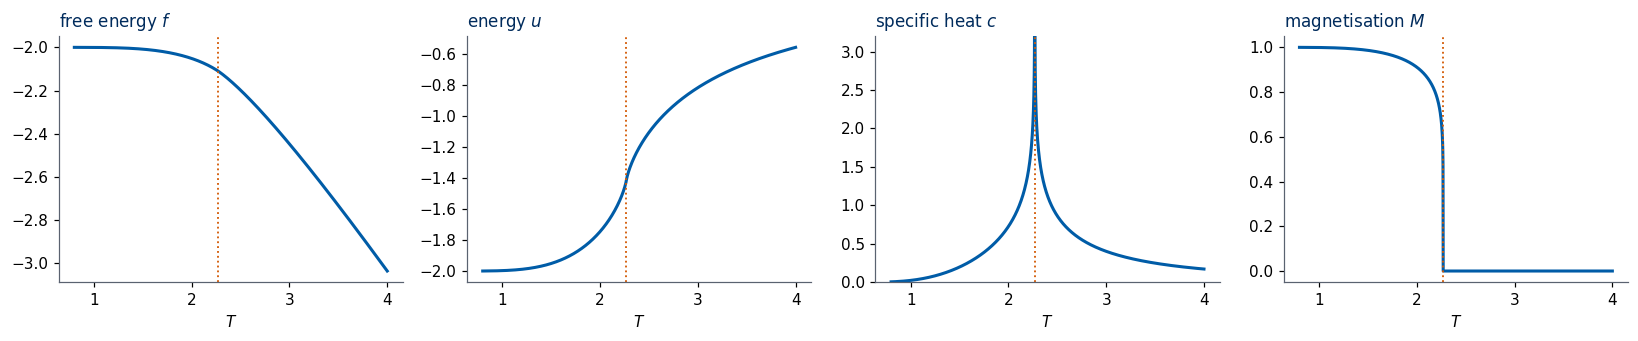

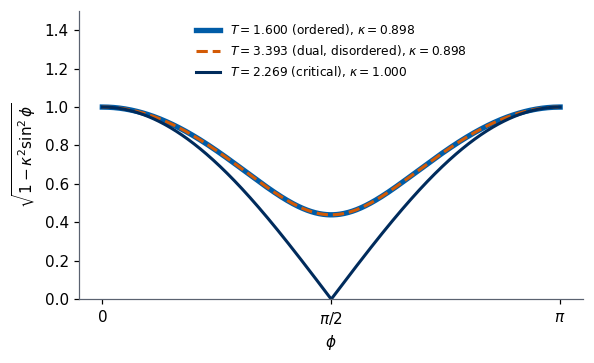

In [27]:
T = np.linspace(0.8, 4.0, 1601); T = T[np.abs(T - TC) > 1e-4]
f = np.array([f_onsager(t) for t in T]); u = u_elliptic(T); c = np.gradient(u, T); M = M_yang(T)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, (y, lab) in zip(axes, [(f, "free energy $f$"), (u, "energy $u$"), (c, "specific heat $c$"), (M, "magnetisation $M$")]):
    if y is c:
        for side in (T < TC, T > TC):
            ax.plot(T[side], y[side], color=UJBlue, lw=2)
        ax.set_ylim(0, 3.2)
    else:
        ax.plot(T, y, color=UJBlue, lw=2)
    ax.axvline(TC, color=DSOrange, ls=":", lw=1.2); ax.set_xlabel("$T$"); ax.set_title(lab, loc="left")
plt.tight_layout(); plt.show()

phi_ = np.linspace(0, np.pi, 801)
T1 = 1.6; T1d = 1 / K_dual(1 / T1)
fig, ax = plt.subplots(figsize=(5.5, 3.4))
for Tv, col, ls, lw, name in [(T1, UJBlue, "-", 3.5, "ordered"), (T1d, DSOrange, "--", 2, "dual, disordered"), (TC, UJNavy, "-", 2, "critical")]:
    k = kappa(1 / Tv)
    ax.plot(phi_, np.sqrt(np.clip(1 - k**2 * np.sin(phi_)**2, 0, None)), color=col, ls=ls, lw=lw,
            label=rf"$T={Tv:.3f}$ ({name}), $\kappa={k:.3f}$")
ax.set_xticks([0, np.pi / 2, np.pi], ["0", r"$\pi/2$", r"$\pi$"]); ax.set_xlabel(r"$\phi$")
ax.set_ylabel(r"$\sqrt{1-\kappa^2\sin^2\phi}$"); ax.set_ylim(0, 1.5); ax.legend(frameon=False, fontsize=8, loc="upper center")
plt.tight_layout(); plt.show()

The free energy $f$ looks perfectly smooth; $u$ is continuous but has a vertical tangent at $T_c$; $c = du/dT$ diverges on both sides; and $M$ drops to zero
continuously but very steeply, with exponent $1/8$. The singularity of $f$ sits in its **second** derivative, and $u$ has no jump (no latent heat): the transition is
continuous, or of second order. The last figure shows the integrand of Onsager's formula. At $T$ and at its dual $T^*$ it is identical (Section 5), and at $T_c$ it touches
zero at $\phi=\pi/2$ with a kink.

<hr/>
## 7. The energy at the critical point

The value of $u$ at $T_c$ is a good test of the whole construction: we can obtain it once from Onsager's solution and once from duality alone, without the solution.
The comparison also shows how much information a symmetry carries.

### 7.1 The critical energy from Onsager's solution
At $T_c$ we have $\sinh 2K_c = 1$, hence $\cosh^2 2K_c = 1+\sinh^22K_c = 2$ and $\tanh^22K_c = \tfrac12$, so the prefactor $2\tanh^22K_c - 1$ vanishes.
In the elliptic formula this prefactor multiplies the divergent $K_1(\kappa\to1)$, and their product vanishes (a linear zero times a logarithmic divergence), so
$u(T_c) = -\coth2K_c = -\cosh 2K_c/\sinh 2K_c = -\sqrt2$. SymPy confirms the two exact values, and the next cell approaches $T_c$ numerically from both sides;
the two sequences close in on $-\sqrt2$ from opposite directions, and the central difference of the integral at $T_c$ gives $-1.41421356$.

In [28]:
# SymPy: the prefactor vanishes and coth 2K_c = sqrt 2
Kc_sym = sp.log(1 + sp.sqrt(2)) / 2
print("2 tanh^2 2K_c - 1 =", sp.simplify((2 * sp.tanh(2 * Kc_sym)**2 - 1).rewrite(sp.exp)))
print("-coth 2K_c        =", sp.radsimp(sp.simplify((-1 / sp.tanh(2 * Kc_sym)).rewrite(sp.exp))))

2 tanh^2 2K_c - 1 = 0
-coth 2K_c        = -sqrt(2)


In [29]:
for eps in (1e-3, 1e-6, 1e-9):
    print(f"u(T_c (1 -/+ {eps:.0e})) = {u_elliptic(TC*(1-eps)):.10f}, {u_elliptic(TC*(1+eps)):.10f}")
print(f"-sqrt(2)                = {-np.sqrt(2):.10f}")
b, db = KC, 1e-5
u_int = ((b + db) * f_onsager(1/(b + db)) - (b - db) * f_onsager(1/(b - db))) / (2 * db)
print(f"from the integral, central difference in beta at T_c: {u_int:.8f}")

u(T_c (1 -/+ 1e-03)) = -1.4223925854, -1.4060346096
u(T_c (1 -/+ 1e-06)) = -1.4142294932, -1.4141976315
u(T_c (1 -/+ 1e-09)) = -1.4142135861, -1.4142135387
-sqrt(2)                = -1.4142135624
from the integral, central difference in beta at T_c: -1.41421356


### 7.2 The critical energy from duality alone
The same number can be obtained without Onsager's formula. Since $\varphi = \ln Z/N$ and $\partial\ln Z/\partial\beta = -\langle H\rangle$, with $J=1$ we have $K=\beta$ and
$$
\varphi'(K) = -u(K) \equiv \varepsilon(K),
$$
where $\varepsilon = 2\langle s_is_j\rangle_{\rm nn}$ is twice the nearest-neighbour correlation (two bonds per spin).
We differentiate the duality identity $\ \varphi(K) - \ln2 - 2\ln\cosh K = \varphi(K^*) - 2K^*\ $ with respect to $K$, using the chain rule on the right:
$$
\varepsilon(K) - 2\tanh K = \big(\varepsilon(K^*) - 2\big)\frac{dK^*}{dK}.
$$
The derivative of the dual map follows from $e^{-2K^*} = \tanh K$: $\ -2e^{-2K^*}dK^* = \frac{dK}{\cosh^2K}$, so
$\frac{dK^*}{dK} = -\frac{1}{2\tanh K\cosh^2K} = -\frac{1}{2\sinh K\cosh K} = -\frac{1}{\sinh 2K}$, which equals $-1$ at $K_c$.

At the self-dual point $K = K^* = K_c$ both sides involve the same $\varepsilon$, provided $u$ is continuous there — no latent heat, as Section 6 showed. Then
$$
\varepsilon - 2\tanh K_c = -(\varepsilon - 2)\ \Rightarrow\ \varepsilon(K_c) = 1 + \tanh K_c .
$$
Finally $\tanh K_c = e^{-2K_c}$ by self-duality, and this equals $1/(1+\sqrt2) = \sqrt2 - 1$, so $\varepsilon(K_c) = \sqrt2$ and $u(T_c) = -\sqrt2$.
Two exact results, $T_c$ and $u(T_c)$, thus follow from a symmetry argument alone. In the next two cells SymPy solves the equation at the self-dual point, and the
numerical check confirms $dK^*/dK = -1$ at $K_c$, the value $\sqrt2-1$, and the differentiated identity also away from $K_c$, where both sides agree to all printed digits.

In [30]:
# SymPy: solve Step 4 for epsilon at the self-dual point
eps_s = sp.symbols("epsilon")
Kc_sym = sp.log(1 + sp.sqrt(2)) / 2
sol = sp.solve(sp.Eq(eps_s - 2 * sp.tanh(Kc_sym), -(eps_s - 2)), eps_s)[0]
print("epsilon(K_c) =", sol, "=", sp.radsimp(sp.simplify(sol.rewrite(sp.exp))), ";   u(T_c) = -epsilon(K_c) =", -sp.radsimp(sp.simplify(sol.rewrite(sp.exp))))

epsilon(K_c) = tanh(log(1 + sqrt(2))/2) + 1 = sqrt(2) ;   u(T_c) = -epsilon(K_c) = -sqrt(2)


In [31]:
h = 1e-7
print(f"dK*/dK at K_c (finite difference) = {(K_dual(KC + h) - K_dual(KC - h)) / (2*h):.8f}   (exact: -1/sinh 2K_c = {-1/np.sinh(2*KC):.8f})")
print(f"tanh K_c = {np.tanh(KC):.12f},  e^(-2K_c) = {np.exp(-2*KC):.12f},  sqrt2 - 1 = {np.sqrt(2)-1:.12f}")
print(f"1 + tanh K_c = {1 + np.tanh(KC):.12f}   vs   -u(T_c) from the elliptic formula = {-u_elliptic(TC*(1+1e-12)):.12f}")
# the differentiated identity at several K (not only at K_c), with epsilon from the elliptic formula
for K in (0.3, 0.4, 0.43, 0.45, 0.5, 0.6):
    Ks = K_dual(K)
    lhs = -u_elliptic(1/K) - 2*np.tanh(K)
    rhs = (-u_elliptic(1/Ks) - 2) * (-1/np.sinh(2*K))
    print(f"K = {K:.4f}:  eps(K) - 2 tanh K = {lhs:+.10f}   (eps(K*) - 2) dK*/dK = {rhs:+.10f}")

dK*/dK at K_c (finite difference) = -1.00000000   (exact: -1/sinh 2K_c = -1.00000000)
tanh K_c = 0.414213562373,  e^(-2K_c) = 0.414213562373,  sqrt2 - 1 = 0.414213562373
1 + tanh K_c = 1.414213562373   vs   -u(T_c) from the elliptic formula = 1.414213562342
K = 0.3000:  eps(K) - 2 tanh K = +0.1218738459   (eps(K*) - 2) dK*/dK = +0.1218738459
K = 0.4000:  eps(K) - 2 tanh K = +0.3461812792   (eps(K*) - 2) dK*/dK = +0.3461812792
K = 0.4300:  eps(K) - 2 tanh K = +0.4897691028   (eps(K*) - 2) dK*/dK = +0.4897691028
K = 0.4500:  eps(K) - 2 tanh K = +0.6692477955   (eps(K*) - 2) dK*/dK = +0.6692477955
K = 0.5000:  eps(K) - 2 tanh K = +0.8213302608   (eps(K*) - 2) dK*/dK = +0.8213302608
K = 0.6000:  eps(K) - 2 tanh K = +0.8349870437   (eps(K*) - 2) dK*/dK = +0.8349870437


<hr/>
## 8. Critical exponents

The critical temperature depends on the lattice; Section 10 will show a different value for the triangular lattice. What does *not* depend on such details is the way
quantities diverge or vanish near $T_c$, described by the **critical exponents**. They are the numbers that characterise a phase transition, and they are what the exact
solution contributes beyond $T_c$. With the reduced temperature $t = (T-T_c)/T_c$ they are defined by
$$
\begin{aligned}
c&\sim|t|^{-\alpha},\qquad M\sim(-t)^{\beta}\ (t<0),\qquad \chi\sim|t|^{-\gamma},\qquad \xi\sim|t|^{-\nu},\\
\langle s_0s_r\rangle&\sim r^{-(d-2+\eta)}\ \text{at } T_c ,
\end{aligned}
$$
where $\chi=\partial m/\partial h$ is the magnetic susceptibility and $d$ the dimension ($d=2$ here, so $\langle s_0s_r\rangle\sim r^{-\eta}$ at $T_c$).
The symbol $\beta$ here denotes an exponent, not $1/T$; the context makes the meaning clear. The 2D Ising model realises the case $\alpha=0$ with a logarithm, $c\sim-\ln|t|$.

For the magnetisation we fit $\ln M$ against $\ln(-t)$ close to $T_c$ and also look at the *local* slope $d\ln M/d\ln(-t)$, which must tend to $\beta$.
For the specific heat we fit $c = -A\ln|t| + B_\pm$ on both sides of $T_c$ and test the amplitude predicted by Onsager's solution,
$A = \frac{2}{\pi}\big(\frac{2}{T_c}\big)^2 = \frac{2}{\pi}(2K_c)^2$ [Onsager 1944]. Here $c$ is obtained from the elliptic $u$ by a central difference with a step much smaller than $|T-T_c|$.

beta from a fit of ln M vs ln(-t), |t| < 1e-4:  0.124999    (1/8 = 0.125)
local slope d lnM / d ln|t| at |t| = 1e-2, 1e-4, 1e-6, 1e-8: 0.12310, 0.12498, 0.12500, 0.12500
T < T_c:  c = -A ln|t| + B  with  A = 0.494517,  B = -0.3060
T > T_c:  c = -A ln|t| + B  with  A = 0.494656,  B = -0.3078
exact amplitude: A = (2/pi)(2/T_c)^2 = 0.494539


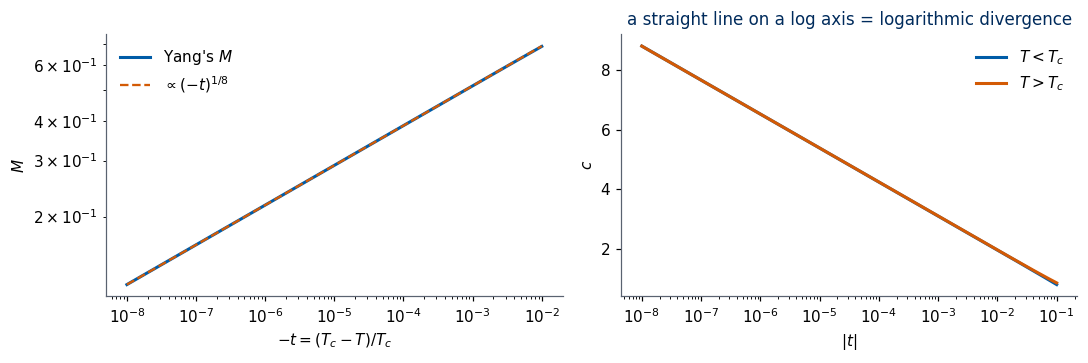

In [32]:
tt = np.logspace(-8, -2, 40)                                   # |t|
Mt = M_yang(TC * (1 - tt))
slope_fit = np.polyfit(np.log(tt[tt < 1e-4]), np.log(Mt[tt < 1e-4]), 1)[0]
local = np.gradient(np.log(Mt), np.log(tt))
print(f"beta from a fit of ln M vs ln(-t), |t| < 1e-4:  {slope_fit:.6f}    (1/8 = {1/8})")
print("local slope d lnM / d ln|t| at |t| = 1e-2, 1e-4, 1e-6, 1e-8:",
      ", ".join(f"{np.interp(np.log(x), np.log(tt), local):.5f}" for x in (1e-2, 1e-4, 1e-6, 1e-8)))

def c_exact(T, rel=1e-4):
    # c = du/dT by a central difference with step rel*|T - T_c|
    hstep = rel * np.abs(T - TC)
    return (u_elliptic(T + hstep) - u_elliptic(T - hstep)) / (2 * hstep)

A_exact = 2 / np.pi * (2 / TC)**2
for side, sgn in (("T < T_c", -1), ("T > T_c", +1)):
    tfit = np.logspace(-9, -4, 30)
    cfit = c_exact(TC * (1 + sgn * tfit))
    A, B = np.polyfit(-np.log(tfit), cfit, 1)
    print(f"{side}:  c = -A ln|t| + B  with  A = {A:.6f},  B = {B:+.4f}")
print(f"exact amplitude: A = (2/pi)(2/T_c)^2 = {A_exact:.6f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].loglog(tt, Mt, color=UJBlue, lw=2, label="Yang's $M$")
ax[0].loglog(tt, tt**0.125 * Mt[0] / tt[0]**0.125, color=DSOrange, ls="--", lw=1.5, label=r"$\propto(-t)^{1/8}$")
ax[0].set_xlabel(r"$-t = (T_c - T)/T_c$"); ax[0].set_ylabel("$M$"); ax[0].legend(frameon=False)
tl = np.logspace(-8, -1, 200)
ax[1].semilogx(tl, c_exact(TC * (1 - tl)), color=UJBlue, lw=2, label="$T<T_c$")
ax[1].semilogx(tl, c_exact(TC * (1 + tl)), color=DSOrange, lw=2, label="$T>T_c$")
ax[1].set_xlabel(r"$|t|$"); ax[1].set_ylabel("$c$"); ax[1].legend(frameon=False)
ax[1].set_title("a straight line on a log axis = logarithmic divergence")  # the two sides nearly coincide: B_- and B_+ are close
plt.tight_layout(); plt.show()

The fit gives $\beta = 0.124999$, and the local slope approaches $1/8$ as $|t|\to0$. The specific-heat amplitudes on the two sides, $0.494517$ and $0.494656$,
agree with the exact $A = 0.494539$, and on the logarithmic axis the two branches of $c$ are straight lines, the signature of a logarithmic divergence.

### 8.1 Finite-size scaling of strips
The strips of Section 3 give two more exponents, independently of Onsager's formula. Both rest on the idea of *finite-size scaling*: near $T_c$ the only relevant
lengths are $\xi$ and the strip width $L$, so dimensionless quantities depend only on their ratio.

At $T_c$ the strip correlation length is proportional to the width, and conformal invariance of the critical point fixes the constant: $\xi_L = L/(\pi\eta)$ on a
periodic strip [Cardy 1984]. The quantity $\eta_L = L/(\pi\,\xi_L(T_c))$ should therefore tend to $\eta$, whose exact value is $\eta = 1/4$.
Near $T_c$, $\xi_L/L$ is a function of $L/\xi\propto L\,|t|^{\nu}$, that is of $L^{1/\nu}t$ only, so its slope at $T_c$ grows as
$\frac{d(\xi_L/L)}{dT}\big|_{T_c}\propto L^{1/\nu}$; the exact value is $\nu = 1$ (Section 6.2: $\xi\propto1/(T-T_c)$).
The free energy at $T_c$ carries a third universal number. It converges as $f_L - f = -\frac{\pi\,c_{\rm CFT}\,T_c}{6L^2}$ [Blöte, Cardy & Nightingale 1986; Affleck 1986],
where $c_{\rm CFT}$ is the central charge of the conformal field theory (CFT) describing the critical point. For the Ising model $c_{\rm CFT} = \frac12$, so $L^2(f_L - f)\to-\pi T_c/12$.
The cell below computes all three quantities for $L = 4,\dots,12$.

In [33]:
print(" L    eta_L = L/(pi xi_L(T_c))   L^2 (f_L - f)(T_c)    slope d(xi_L/L)/dT at T_c")
slopes, Lv = [], [4, 6, 8, 10, 12]
t0 = time.perf_counter()
for L in Lv:
    l0, l1 = lambda01(L, KC)
    xi = 1 / np.log(l0 / l1)
    dT = 1e-4
    s = (xi_over_L(L, TC + dT) - xi_over_L(L, TC - dT)) / (2 * dT)
    slopes.append(abs(s))
    print(f"{L:2d}       {L/(np.pi*xi):.6f}               {L**2 * (-TC*np.log(l0)/L - f_onsager(TC)):+.6f}            {s:+.4f}")
print(f"(computed in {time.perf_counter()-t0:.1f} s)        -pi T_c/12 = {-np.pi*TC/12:.6f}")
inv_nu = np.diff(np.log(slopes)) / np.diff(np.log(Lv))
print("1/nu from consecutive pairs of L:", ", ".join(f"{v:.4f}" for v in inv_nu))

 L    eta_L = L/(pi xi_L(T_c))   L^2 (f_L - f)(T_c)    slope d(xi_L/L)/dT at T_c
 4       0.257845               -0.620440            -2.3677
 6       0.253121               -0.604507            -3.6854
 8       0.251679               -0.599671            -4.9703
10       0.251056               -0.597589            -6.2438


12       0.250727               -0.596492            -7.5122
(computed in 3.5 s)        -pi T_c/12 = -0.594071
1/nu from consecutive pairs of L: 1.0912, 1.0397, 1.0222, 1.0144


All three columns converge monotonically in $L$ towards the exact values: $\eta_L$ falls from $0.257845$ to $0.250727$, $L^2(f_L-f)$ approaches $-\pi T_c/12 = -0.594071$,
and the estimates of $1/\nu$ from consecutive pairs of widths decrease from $1.0912$ to $1.0144$. The exponents are not independent of one another. Two *scaling relations*
[Kardar 2007], the Fisher relation $\gamma = \nu(2-\eta)$ and the Rushbrooke relation $\alpha + 2\beta + \gamma = 2$, give the remaining exponent $\gamma$ and a consistency check.

In [34]:
nu, eta, alpha, beta_ = 1, 0.25, 0, 0.125
gamma = nu * (2 - eta)
print(f"gamma = nu (2 - eta) = {gamma}   (= 7/4);   Rushbrooke check alpha + 2 beta + gamma = {alpha + 2*beta_ + gamma}")

gamma = nu (2 - eta) = 1.75   (= 7/4);   Rushbrooke check alpha + 2 beta + gamma = 2.0


The relations give $\gamma = 7/4$, and the Rushbrooke sum equals 2 as it should.

These exponents complete the phase diagram of the model, drawn below. A phase diagram is a map of the control parameters, here the temperature $T$ and the magnetic field $h$ of Section 1, divided into regions with qualitatively different behaviour, the phases, and the lines between them, the phase transitions.

The type of a transition is read off from the free energy per spin $f(T,h)$ and its derivatives, such as the magnetisation $m=-\partial f/\partial h$ and the energy. At a **first-order** transition a first derivative of $f$ jumps: the order parameter changes discontinuously and the two phases coexist at the transition. At a **continuous** (or second-order) transition the first derivatives are continuous, the order parameter goes to zero continuously, and the correlation length $\xi$, the distance over which spins influence each other, diverges as a power of the distance to the critical point, $\xi\sim|T-T_c|^{-\nu}$; second derivatives such as the specific heat and the susceptibility then diverge or have a cusp.

In panel (a) the segment $h=0$, $T<T_c$ is a line of first-order transitions: when $h$ changes sign below $T_c$, the magnetisation $m=-\partial f/\partial h$ jumps from $-M$ to $+M$. The line ends at the critical point $T_c=2/\ln(1+\sqrt2)=2.269$, $h=0$, and above $T_c$ the magnetisation changes smoothly with $h$. Panel (b) is the temperature axis at $h=0$ with Yang's exact magnetisation $\pm M(T)$ (Section 6.3). At $T_c$ the transition is continuous, with the exponents computed in this section: $\beta=1/8$, $\nu=1$, $\gamma=7/4$ and $\alpha=0$ with a logarithmic specific heat. Every model with the same symmetry (a two-state order parameter) and dimension $d=2$ and short-range interactions shares them; this set of models is the two-dimensional Ising universality class, and Section 10 tests it on the triangular lattice.

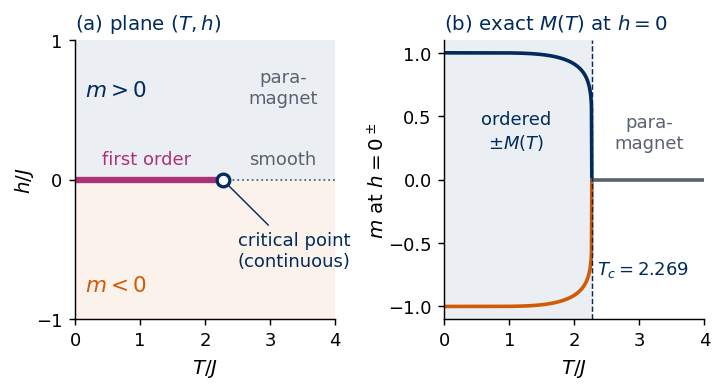

In [ ]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("figures", exist_ok=True)
    for d in ("figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def sketch_ising_phase_diagram():
    Tc = 2.0 / np.log(1.0 + np.sqrt(2.0))                         # exact critical temperature (J = k_B = 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(5.5, 2.9))
    fig.subplots_adjust(left=0.1, right=0.98, bottom=0.16, top=0.9, wspace=0.42)

    # (a) the (T, h) plane: a first-order line on h = 0 that ends at the critical point
    ax1.fill_between([0, 4], 0, 1, color=NAVY, alpha=0.08, lw=0); ax1.fill_between([0, 4], -1, 0, color=ORANGE, alpha=0.08, lw=0)
    ax1.plot([0, Tc], [0, 0], color=PURPLE, lw=3.5, solid_capstyle="butt")
    ax1.plot([Tc, 4], [0, 0], color=GRAY, lw=1, ls=":")
    ax1.plot(Tc, 0, "o", ms=7, mfc="white", mec=NAVY, mew=1.8, zorder=5)
    ax1.text(0.15, 0.6, "$m>0$", fontsize=12, color=NAVY); ax1.text(0.15, -0.8, "$m<0$", fontsize=12, color=ORANGE)
    ax1.text(1.1, 0.08, "first order", fontsize=10, color=PURPLE, ha="center", va="bottom")
    ax1.text(3.2, 0.08, "smooth", fontsize=10, color=GRAY, ha="center", va="bottom")
    ax1.text(3.2, 0.55, "para-\nmagnet", fontsize=10, color=GRAY, ha="center")
    ax1.annotate("critical point\n(continuous)", xy=(Tc, 0), xytext=(2.5, -0.62), fontsize=10, color=NAVY, ha="left",
                 arrowprops=dict(arrowstyle="-", color=NAVY, lw=0.8))
    ax1.set_xlim(0, 4); ax1.set_ylim(-1, 1); ax1.set_xticks([0, 1, 2, 3, 4]); ax1.set_yticks([-1, 0, 1])
    ax1.set_xlabel("$T/J$"); ax1.set_ylabel("$h/J$", labelpad=0)
    ax1.set_title("(a) plane $(T,h)$", fontsize=11, color=NAVY, loc="left")

    # (b) the temperature axis at h = 0 with the exact spontaneous magnetisation of Onsager and Yang
    T = np.linspace(0.02, Tc, 400)
    M = np.clip(1.0 - np.sinh(2.0 / T) ** -4, 0, None) ** 0.125
    ax2.axvspan(0, Tc, color=NAVY, alpha=0.08, lw=0)
    ax2.plot(T, M, color=NAVY, lw=2); ax2.plot(T, -M, color=ORANGE, lw=2); ax2.plot([Tc, 4], [0, 0], color=GRAY, lw=2)
    ax2.axvline(Tc, color=NAVY, lw=0.8, ls="--")
    ax2.text(1.1, 0.25, "ordered\n$\\pm M(T)$", fontsize=10, color=NAVY, ha="center")
    ax2.text(3.15, 0.25, "para-\nmagnet", fontsize=10, color=GRAY, ha="center")
    ax2.text(Tc + 0.08, -0.75, f"$T_c={Tc:.3f}$", fontsize=10, color=NAVY)
    ax2.set_xlim(0, 4); ax2.set_ylim(-1.1, 1.1); ax2.set_xticks([0, 1, 2, 3, 4])
    ax2.set_xlabel("$T/J$"); ax2.set_ylabel("$m$ at $h=0^\\pm$", labelpad=0)
    ax2.set_title("(b) exact $M(T)$ at $h=0$", fontsize=11, color=NAVY, loc="left")
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_ising_phase_diagram()
save_sketch(fig, "sketch_ising_phases.png")
plt.show()


<hr/>
## 9. Mean-field theory and the exact solution

Mean-field theory is the approximation one uses when no exact solution exists. With the exact solution at hand we can measure precisely what it gets wrong, and why.

Spin $i$ interacts with its $z$ neighbours ($z=4$ on the square lattice) through $-Js_i\sum_{j\in{\rm nn}(i)}s_j$. Mean-field theory replaces each neighbour by its
average $m=\langle s_j\rangle$, so that spin $i$ feels an effective field $zJm$; a single spin in a field $B$ has $\langle s\rangle = \tanh(\beta B)$.
Self-consistency, $\langle s_i\rangle = m$, then gives with $J=1$
$$
m = \tanh\Big(\frac{zm}{T}\Big) = \tanh\Big(\frac{4m}{T}\Big).
$$
The value $m = 0$ is always a solution. A non-zero one exists when the slope of the right-hand side at $m = 0$ exceeds 1, i.e. $4/T > 1$, so $T_c^{\rm MF} = z = 4$.
Near $T_c^{\rm MF}$, $\tanh x\approx x - x^3/3$ gives $m \approx \frac4Tm - \frac13\big(\frac4T\big)^3m^3$, i.e. $m^2\approx 3\big(\frac4T-1\big)\big/\big(\frac4T\big)^3$,
so $m\sim(1 - T/T_c^{\rm MF})^{1/2}$ and $\beta_{\rm MF} = \frac12$.
For the energy, replacing $s_is_j$ by $m^2$ in each of the $zN/2$ bonds gives $u_{\rm MF} = -\frac z2m^2 = -2m^2$. It is zero above $T_c^{\rm MF}$ and has a finite
slope below, which produces a **jump** in $c$ instead of a divergence.

The replacement assumes $\langle s_is_j\rangle = \langle s_i\rangle\langle s_j\rangle$, that is, no correlations. Near $T_c$ the correlation length diverges and correlated
fluctuations dominate, so the approximation must fail there. In 1D ($z=2$) it even predicts a transition at $T=2$, where the exact chain has none (Section 2).
Mean-field exponents become exact only in high dimensions, above the upper critical dimension $d=4$ of the Ising model [Kardar 2007].
SymPy reproduces the expansion of the self-consistency equation, and the following cell solves it numerically, fits $\beta_{\rm MF}$, evaluates the jump of the specific
heat and compares the mean-field magnetisation with Yang's.

In [35]:
# SymPy: m tanh-expansion near T_c^MF, with a = z/T = 4/T
m, a = sp.symbols("m a", positive=True)
cubic = sp.series(sp.tanh(a * m), m, 0, 4).removeO()                     # a m - a^3 m^3 / 3
print("tanh(a m) =", cubic, "+ O(m^5)")
print("non-zero solution of m = a m - a^3 m^3/3:  m =", sp.solve(sp.Eq(cubic / m, 1), m))

tanh(a m) = -a**3*m**3/3 + a*m + O(m^5)
non-zero solution of m = a m - a^3 m^3/3:  m = [sqrt(3)*sqrt(a - 1)/a**(3/2)]


T_c (mean field, numerical) = 4.000000     exact 2D: T_c = 2.269185     ratio = 1.7627
beta_MF from a fit near T_c^MF: 0.49998
mean-field specific heat just below T_c^MF: 1.49640, 1.49996   (and exactly 0 above)


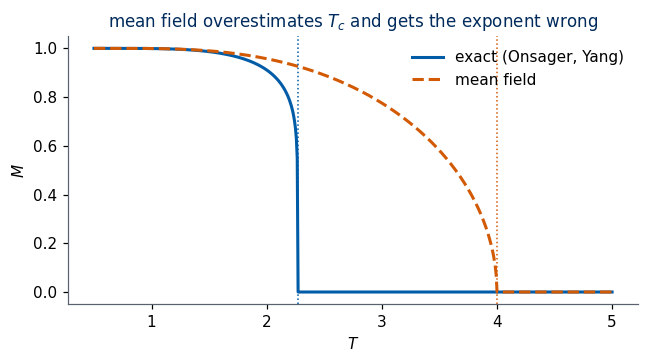

In [36]:
def m_meanfield(T):
    # largest solution of m = tanh(4 m / T)
    if 4 / T <= 1:
        return 0.0
    return brentq(lambda m: m - np.tanh(4 * m / T), 1e-12, 1.0)

# T_c^MF: the largest T with a non-zero solution (found by bisection, threshold m > 1e-6)
lo, hi = 2.0, 6.0
for _ in range(80):
    mid = 0.5 * (lo + hi)
    lo, hi = (mid, hi) if m_meanfield(mid) > 1e-6 else (lo, mid)
print(f"T_c (mean field, numerical) = {lo:.6f}     exact 2D: T_c = {TC:.6f}     ratio = {lo/TC:.4f}")

tt = np.logspace(-8, -3, 20)
mf = np.array([m_meanfield(4 * (1 - x)) for x in tt])
print(f"beta_MF from a fit near T_c^MF: {np.polyfit(np.log(tt), np.log(mf), 1)[0]:.5f}")
cm = [(-2*m_meanfield(4*(1-x))**2 + 2*m_meanfield(4*(1-2*x))**2) / (4*x) for x in (1e-3, 1e-5)]
print("mean-field specific heat just below T_c^MF:", ", ".join(f"{v:.5f}" for v in cm), "  (and exactly 0 above)")

T = np.linspace(0.5, 5, 600)
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(T, M_yang(T), color=UJBlue, lw=2, label="exact (Onsager, Yang)")
ax.plot(T, [m_meanfield(t) for t in T], color=DSOrange, lw=2, ls="--", label="mean field")
ax.axvline(TC, color=UJBlue, ls=":", lw=1); ax.axvline(4, color=DSOrange, ls=":", lw=1)
ax.set_xlabel("$T$"); ax.set_ylabel("$M$"); ax.legend(frameon=False)
ax.set_title("mean field overestimates $T_c$ and gets the exponent wrong")
plt.tight_layout(); plt.show()

The numbers make the failure quantitative: mean field puts $T_c$ at $4$, a factor $1.7627$ above the exact value, its exponent comes out as $0.49998\approx\frac12$, and
its specific heat jumps to about $1.5$ instead of diverging. Mean field neglects fluctuations, and in 2D they are strong: they lower $T_c$ from $4$ to $2.269$, change
$\beta$ from $\frac12$ to $\frac18$, and turn the jump in $c$ into a logarithmic divergence. The same self-consistency equation $m=\tanh(\cdot)$ reappears in the
energy-based models of the course, as the update rule of a recurrent $\tanh$ network.

<hr/>
## 10. Universality and the triangular lattice

Section 8 claimed that the exponents, unlike $T_c$, do not depend on lattice details, and we now test this on a different lattice. Exponents depend only on the
dimension, on the symmetry of the order parameter (here $s\to-s$) and on the range of the interactions [Kardar 2007]; models sharing these form a **universality class**.

Add one diagonal bond to every plaquette: each spin now has $z = 6$ neighbours and the lattice becomes triangular. In the transfer matrix this is the extra term
$K\sum_is_is'_{i+1}$ (flag `lattice="triangular"`); $\mathsf V$ is then no longer symmetric, so we use a general eigensolver. The exact critical temperature is
$T_c^{\triangle} = 4/\ln3$ [Houtappel 1950], and the exponents should be those of the square lattice. We test both with the crossing method of Section 3 and with $\eta_L$ of Section 8.1.

One geometric detail must be taken into account. In the triangular lattice the columns are $\sqrt3/2$ apart while the sites of one column are at distance 1, so the
physical correlation length is $\frac{\sqrt3}{2}\xi_L$ and $\eta_L = L\big/\big(\pi\,\tfrac{\sqrt3}{2}\xi_L\big)$.

In [37]:
print(" L, L+2   crossing T*(L)     eta at the crossing")
t0 = time.perf_counter()
for L in (4, 6, 8, 10):
    Tx = brentq(lambda T: xi_over_L(L, T, "triangular") - xi_over_L(L + 2, T, "triangular"), 3.0, 4.2, xtol=1e-12)
    xi = xi_over_L(L + 2, Tx, "triangular") * (L + 2)
    print(f"{L:2d}, {L+2:2d}   {Tx:.8f}       {(L + 2) / (np.pi * np.sqrt(3) / 2 * xi):.5f}")
print(f"4/ln 3 = {4/np.log(3):.8f}    ({time.perf_counter()-t0:.1f} s)")

 L, L+2   crossing T*(L)     eta at the crossing
 4,  6   3.64236593       0.25076
 6,  8   3.64117712       0.25016


 8, 10   3.64101598       0.25006


10, 12   3.64097803       0.25002
4/ln 3 = 3.64095691    (20.9 s)


The crossings converge to $3.64097803$ for the widths $(10,12)$, against $4/\ln3 = 3.64095691$, and $\eta$ at the crossing approaches $0.25$, ending at $0.25002$.
The critical temperature is different (more neighbours, more order), while the exponent $\eta$ is the same: $T_c$ is a lattice detail, the exponents are
universal. A network trained on one lattice can transfer to another lattice only to the extent that it has learned something universal — the
interpretability question raised in the lecture.

<hr/>
## 11. Map of the derivations

The table collects the statements of this notebook and the place where each is derived and verified.

| statement | where it is derived and checked |
|---|---|
| all thermodynamics from $\ln Z$; $c$ = energy variance; finite lattice ⇒ $\ln Z$ analytic | Section 1 (brute force, $4\times4$) |
| $Z = \operatorname{Tr}\mathsf T^N$, $\lambda_\pm = 2\cosh K, 2\sinh K$, $\xi_{1D}=-1/\ln\tanh K$ finite: no transition in 1D | Section 2 |
| $Z=\operatorname{Tr}\mathsf V^{L'}$, $f_L\to f$, $c_L$ peak grows, $\xi_L/L$ crossings $\to T_c$; 1D vs 2D, domain walls | Section 3 |
| closed graphs and domain walls: $1 + Nt^4 + 2Nt^6$ and $1+Nx^4+2Nx^6$ | Section 4 |
| $\sinh2K\sinh2K^* = 1$, $\kappa(K) = \kappa(K^*)$, $\sinh 2K_c = 1$ | Section 5 |
| Pauli form, Jordan–Wigner fermions, $2\times2$ blocks, Kaufman's $\lambda_0,\lambda_1$; gap $2\lvert K-K^*\rvert$; $u$ from the integral = elliptic formula | Section 6 |
| $u(T_c) = -\sqrt2$, also from duality | Section 7 |
| $\beta = 1/8$, $\alpha = 0$ (log, amplitude), $\eta = 1/4$, $\nu = 1$, $\gamma=7/4$ | Section 8 |
| $T_c^{\rm MF} = 4$, $\beta_{\rm MF} = 1/2$, jump in $c$ | Section 9 |
| triangular lattice: $T_c = 4/\ln3$, same $\eta$ | Section 10 |
<hr/>
## Exercises

### Exercise 1 — the 1D chain in a field
Using the transfer matrix, compute the magnetisation per spin of the infinite chain, $m = \partial\ln\lambda_+/\partial\tilde h$, numerically (by a finite
difference) and compare it with the closed form $m = \dfrac{\sinh\tilde h}{\sqrt{\sinh^2\tilde h + e^{-4K}}}$. Plot $m(h)$ at several $T$ and decide whether
there is a spontaneous magnetisation at $h\to0^+$ for any $T>0$.

#### Solution

K = 0.5, beta h = 0.1:  m numerical = 0.26271701,  closed form = 0.26271701
K = 1.0, beta h = 0.05:  m numerical = 0.34668443,  closed form = 0.34668443
K = 2.0, beta h = 0.01:  m numerical = 0.47921470,  closed form = 0.47921470


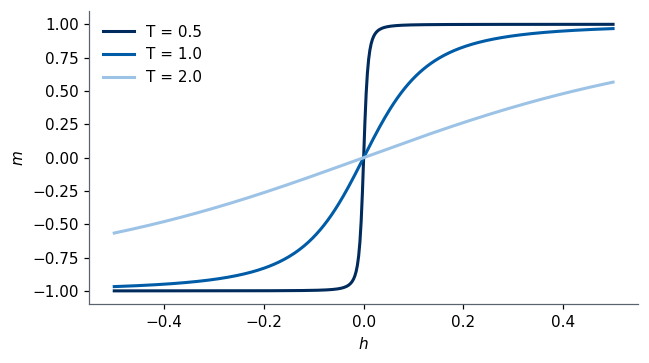

In [38]:
def lam_plus(K, ht):
    return np.exp(K) * np.cosh(ht) + np.sqrt(np.exp(2 * K) * np.sinh(ht)**2 + np.exp(-2 * K))

for K, ht in [(0.5, 0.1), (1.0, 0.05), (2.0, 0.01)]:
    d = 1e-6
    m_num = (np.log(lam_plus(K, ht + d)) - np.log(lam_plus(K, ht - d))) / (2 * d)
    m_cf = np.sinh(ht) / np.sqrt(np.sinh(ht)**2 + np.exp(-4 * K))
    print(f"K = {K}, beta h = {ht}:  m numerical = {m_num:.8f},  closed form = {m_cf:.8f}")

hgrid = np.linspace(-0.5, 0.5, 401)
fig, ax = plt.subplots(figsize=(6, 3.4))
for T, col in [(0.5, UJNavy), (1.0, UJBlue), (2.0, "#9CC3E6")]:
    K = 1 / T; ht = hgrid / T
    ax.plot(hgrid, np.sinh(ht) / np.sqrt(np.sinh(ht)**2 + np.exp(-4 * K)), color=col, lw=2, label=f"T = {T}")
ax.set_xlabel("$h$"); ax.set_ylabel("$m$"); ax.legend(frameon=False); plt.tight_layout(); plt.show()

The curve $m(h)$ is a smooth odd function with $m(0) = 0$ for every $T>0$. There is no spontaneous magnetisation, only an ever steeper curve as $T\to0$:
the slope at $h = 0$ is $\beta e^{2K}$, which grows exponentially in $K$ but stays finite for every $T>0$.

### Exercise 2 — the specific-heat peak of strips
Using `strip` from Section 3, plot the maximum of $c_L$ against $\ln L$. A logarithmic divergence $c\sim-A\ln|t|$ combined with $|t|\sim1/L$
(because $\nu = 1$) predicts $c_{\max}(L)\approx A\ln L + \text{const}$. Fit the slope and compare it with the amplitude $A$ found in Section 8.

#### Solution

In [39]:
cmax = []
t0 = time.perf_counter()
Lex = [4, 6, 8, 10, 12]
for L in Lex:
    if L in strip:
        cmax.append(strip[L]["c"][2:-2].max())
    else:                                     # L = 12 was not in the scan: maximise c_L near its peak
        def cL(T, L=L, d=2e-3):
            fm, f0, fp = (-(T + s) * np.log(lambda01(L, 1 / (T + s))[0]) / L for s in (-d, 0, d))
            return -T * (fp - 2 * f0 + fm) / d**2
        from scipy.optimize import minimize_scalar
        res = minimize_scalar(lambda T: -cL(T), bounds=(2.24, 2.30), method="bounded", options={"xatol": 1e-3})
        cmax.append(-res.fun)
print(f"(L = 12 peak search: {time.perf_counter()-t0:.1f} s)")
slope = np.polyfit(np.log(Lex[1:]), cmax[1:], 1)[0]
for L, cm in zip(Lex, cmax):
    print(f"L = {L:2d}: c_max = {cm:.4f}")
print(f"slope of c_max vs ln L (L = 6..12): {slope:.4f};   A from Section 8: {A_exact:.4f}")

(L = 12 peak search: 18.2 s)
L =  4: c_max = 0.8728
L =  6: c_max = 1.0739
L =  8: c_max = 1.2160
L = 10: c_max = 1.3262
L = 12: c_max = 1.4170
slope of c_max vs ln L (L = 6..12): 0.4947;   A from Section 8: 0.4945


The slope, $0.4947$ for $L = 6,\dots,12$, approaches $A = 0.4945$; the smallest strips still carry visible corrections. The specific-heat peak of a finite lattice
grows only **logarithmically** with its size, which is one reason why a Monte Carlo study (and the CNN of Lab 011) sees a broad, shifted feature rather than a sharp singularity.

### Exercise 3 (open) — the quantum connection
Section 6.1 used the identity $e^{K}\mathbb 1 + e^{-K}\sigma^x = \sqrt{2\sinh2K}\;e^{K^*\sigma^x}$ to write the strip transfer matrix as
$\mathsf V = (2\sinh2K)^{L/2}\,\mathsf V_2^{1/2}\mathsf V_1\mathsf V_2^{1/2}$: a classical Ising coupling along the column and a **transverse field** of strength $K^*$.
Prove the identity and verify it numerically for a few values of $K$. This is the bridge to the transverse-field Ising chain used later in the course.

#### Solution

In [40]:
sx = np.array([[0.0, 1.0], [1.0, 0.0]])
from scipy.linalg import expm
for K in (0.2, KC, 0.8):
    lhs = np.exp(K) * np.eye(2) + np.exp(-K) * sx
    rhs = np.sqrt(2 * np.sinh(2 * K)) * expm(K_dual(K) * sx)
    print(f"K = {K:.4f}:  max |lhs - rhs| = {np.abs(lhs - rhs).max():.1e}")

K = 0.2000:  max |lhs - rhs| = 1.1e-16
K = 0.4407:  max |lhs - rhs| = 2.2e-16
K = 0.8000:  max |lhs - rhs| = 1.1e-16


In [41]:
# SymPy: the same identity symbolically (coefficients of 1 and sigma^x)
K = sp.symbols("K", positive=True)
K_star = -sp.log(sp.tanh(K)) / 2
pref = sp.sqrt(2 * sp.sinh(2 * K))
print("coefficient of 1      :", sp.simplify((pref * sp.cosh(K_star) - sp.exp(K)).rewrite(sp.exp)))
print("coefficient of sigma^x:", sp.simplify((pref * sp.sinh(K_star) - sp.exp(-K)).rewrite(sp.exp)))

coefficient of 1      : 0
coefficient of sigma^x: 0


For the proof, note that $e^{K^*\sigma^x} = \cosh K^*\,\mathbb1 + \sinh K^*\sigma^x$ because $(\sigma^x)^2=\mathbb 1$. The ratio of the two coefficients must be
$e^{-K}/e^{K}=e^{-2K}$, and indeed $\tanh K^* = e^{-2K}$ (Section 5). For the prefactor, $\cosh^2K^* = 1/(1-\tanh^2K^*) = 1/(1-e^{-4K}) = e^{2K}/(2\sinh2K)$,
so $\sqrt{2\sinh2K}\cosh K^* = e^{K}$. At the self-dual point $K = K^* = K_c$ the column coupling and the transverse field are equal, which is the critical point of the quantum chain.